# Project B04: Pola Penggunaan Perangkat Rumah Pintar

- **Project ID:** B04
- **Kelas:** IF-B PAGI
- **Metode:** Clustering (Unsupervised Learning)
- **Dataset:** Smart Home Dataset with Weather Information (Kaggle, taranvee)

**Anggota:**

- Ipaldi Sembiring (231112081) (Ketua)
- Mikkael Raynala Tampubolon (231112313)
- Muhammad Dhani Irvansyah (231112747)


Tidak perlu mengunggah file karena dataset diunduh otomatis dari Kaggle lewat `kagglehub` pada sel kode pertama

Sumber dataset: https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information (file HomeC.csv).

# A. Problem

## Rumusan Masalah
Pola penggunaan perangkat listrik di rumah pintar berbeda-beda menurut waktu dan kondisi cuaca,
tetapi pola tersebut belum diketahui secara jelas dari data konsumsi mentah. Tanpa pemahaman
pola ini, sulit mengidentifikasi kebiasaan penggunaan energi dan peluang penghematan.

## Tujuan
Mengelompokkan jam-jam penggunaan listrik rumah pintar ke dalam beberapa cluster yang
memiliki karakteristik konsumsi perangkat serupa, lalu menginterpretasikan setiap cluster
sebagai pola penggunaan perangkat.

## Target
Tidak ada target (label) karena ini adalah unsupervised learning.
Keluaran yang diharapkan: label cluster untuk setiap jam beserta profil karakteristik tiap cluster.

## Fitur
- Konsumsi daya per perangkat/ruangan (kW), mis. Furnace, Fridge, Home office, Dishwasher, Barn, dll.
- Fitur waktu: jam (diubah ke sin dan cos) dan penanda akhir pekan (hasil feature engineering)
- Fitur cuaca: suhu, kelembapan, kecepatan angin, tutupan awan, tekanan, jarak pandang

## Jenis Masalah
Unsupervised Learning (Clustering), dengan K-Means sebagai baseline.

## Alasan Masalah Penting
Penelitian rumah berkelanjutan didorong oleh kenaikan harga energi dan kekhawatiran terhadap perubahan iklim [1]. Data konsumsi listrik rumah tangga berskala halus dapat dimanfaatkan untuk memahami penggunaan energi, tetapi pola di dalamnya tidak terlihat langsung dari data mentah. Teknik clustering digunakan dalam penelitian beban listrik untuk menggali pola konsumsi energi yang mendasarinya, dan berbagai algoritma seperti K-Means, hierarchical, dan Gaussian Mixture Model telah dibandingkan untuk keperluan ini [2]. Project ini menerapkan pendekatan serupa pada data satu rumah pintar untuk mengenali pola penggunaan perangkatnya.

## Batasan Proyek
- Data berasal dari satu rumah (satu lokasi dan satu periode sekitar 350 hari), sehingga hasil tidak digeneralisasi ke rumah lain.
- Pendekatan hanya classical machine learning (K-Means, GMM, Agglomerative Clustering, dan PCA), sesuai ruang lingkup mata kuliah.
- Masalah bersifat tanpa label, sehingga kualitas cluster dinilai dengan metrik internal dan interpretasi manual, bukan akurasi.
- Unit observasi adalah satu jam hasil agregasi dari data per menit. Interval waktu dan zona waktu merupakan asumsi dari pola data.
- Project ini mengelompokkan pola penggunaan, bukan memprediksi konsumsi. Dataset dan masalah tidak diganti selama proyek.
- Pada Milestone 1, tuning menyeluruh dan pemilihan model final belum dilakukan.


# B. Dataset

## Sumber
Smart Home Dataset with Weather Information (Kaggle, pengunggah: taranvee)
https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information
File yang digunakan: HomeC.csv

## Ukuran dan Struktur
- Jumlah data mentah: 503.911 baris dan 32 kolom (503.910 baris valid)
- Unit observasi mentah: satu baris per menit (asumsi, lihat Kualitas Data nomor 1)
- Unit observasi untuk modeling: satu jam (rata-rata dari data per menit)
- Rentang waktu: sekitar 350 hari (1 Januari - 15 Desember 2016)

## Fitur
- Waktu: time
- Listrik (kW): use, gen, House overall, Solar
- Per perangkat/ruangan (kW): Dishwasher, Furnace 1, Furnace 2, Home office, Fridge, Wine cellar, Garage door, Kitchen 12, Kitchen 14, Kitchen 38, Barn, Well, Microwave, Living room
- Cuaca: temperature, humidity, visibility, apparentTemperature, pressure, windSpeed, cloudCover, windBearing, precipIntensity, dewPoint, precipProbability, icon, summary

## Target
Tidak ada target karena masalahnya adalah unsupervised learning (clustering).

## Kualitas Data
1. Kolom time berisi Unix timestamp yang naik 1 per baris, sehingga jika dibaca apa adanya hanya mencakup sekitar 5,8 hari. Dari jumlah baris (503.910 / 1.440 = sekitar 350 hari) dan cuaca yang berubah rata-rata tiap sekitar 58 baris, disimpulkan bahwa 1 baris = 1 menit. Ini asumsi berdasarkan pola data, bukan keterangan resmi dataset.
2. Satu baris terakhir tidak valid (time berisi karakter "\" dan semua kolom lain kosong).
3. Kolom cloudCover bertipe teks karena ada 58 baris yang berisi kata "cloudCover" (header yang terselip).
4. Kolom use [kW] identik dengan House overall [kW], dan gen [kW] identik dengan Solar [kW].
5. Kolom Kitchen 38 [kW] hampir selalu nol (rata-rata sekitar 0,000009).
6. Tidak ada data duplikat.
7. Jumlah konsumsi semua perangkat hanya berkorelasi 0,66 dengan use [kW], sehingga tidak semua beban rumah tercatat per perangkat.

## Deskripsi Fitur yang Dipakai (22)
| Kelompok | Fitur | Deskripsi | Satuan |
|----------|-------|-----------|--------|
| Perangkat (13) | Dishwasher, Furnace 1, Furnace 2, Home office, Fridge, Wine cellar, Garage door, Kitchen 12, Kitchen 14, Barn, Well, Microwave, Living room | Rata-rata daya listrik per jam pada sirkuit atau perangkat yang bersangkutan | kW (dari nama kolom) |
| Cuaca (6) | temperature | Suhu luar | dugaan derajat Fahrenheit (rentang sekitar 20 sampai 80) |
| | humidity | Kelembapan relatif | pecahan 0 sampai 1 |
| | windSpeed | Kecepatan angin | dugaan mph |
| | cloudCover | Tutupan awan | pecahan 0 sampai 1 |
| | pressure | Tekanan udara | dugaan milibar (sekitar 1.010 sampai 1.020) |
| | visibility | Jarak pandang | dugaan mil |
| Waktu (3, hasil feature engineering) | hour_sin, hour_cos | Jam dalam sehari yang diubah ke sin dan cos agar jam 23 dan jam 0 berdekatan | tanpa satuan |
| | weekend | Penanda akhir pekan (1 = Sabtu atau Minggu, 0 = hari kerja) | biner |

Kolom yang tidak dipakai sebagai fitur: use dan gen (use identik dengan House overall, gen identik dengan Solar, sehingga redundan atau bukan penggunaan perangkat), Kitchen 38 (hampir selalu nol), apparentTemperature, windBearing, precipIntensity, dewPoint, precipProbability (tidak dipilih untuk penyederhanaan), serta icon dan summary (teks yang mengulang informasi cuaca).

In [ ]:
import kagglehub
import pandas as pd, numpy as np


path = kagglehub.dataset_download("taranvee/smart-home-dataset-with-weather-information")
df_raw = pd.read_csv(path + "/HomeC.csv", low_memory=False)
print("Jumlah baris, kolom:", df_raw.shape)


df_raw.info()
display(df_raw.head())
print("Baris dengan nilai hilang:", df_raw.isna().any(axis=1).sum())
print("Duplikat:", df_raw.duplicated().sum())
print("use == House overall:", np.allclose(df_raw["use [kW]"].dropna(), df_raw["House overall [kW]"].dropna()))
print("gen == Solar:", np.allclose(df_raw["gen [kW]"].dropna(), df_raw["Solar [kW]"].dropna()))

100%|██████████| 19.4M/19.4M [00:00<00:00, 81.3MB/s]

Extracting files...


Jumlah baris, kolom: (503911, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503911 entries, 0 to 503910
Data columns (total 32 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   time                 503911 non-null  object 
 1   use [kW]             503910 non-null  float64
 2   gen [kW]             503910 non-null  float64
 3   House overall [kW]   503910 non-null  float64
 4   Dishwasher [kW]      503910 non-null  float64
 5   Furnace 1 [kW]       503910 non-null  float64
 6   Furnace 2 [kW]       503910 non-null  float64
 7   Home office [kW]     503910 non-null  float64
 8   Fridge [kW]          503910 non-null  float64
 9   Wine cellar [kW]     503910 non-null  float64
 10  Garage door [kW]     503910 non-null  float64
 11  Kitchen 12 [kW]      503910 non-null  float64
 12  Kitchen 14 [kW]      503910 non-null  float64
 13  Kitchen 38 [kW]      503910 non-null  float64
 14  Barn [kW]            503910 non-nu

,time,use [kW],gen [kW],House overall [kW],Dishwasher [kW],Furnace 1 [kW],Furnace 2 [kW],Home office [kW],Fridge [kW],Wine cellar [kW],...,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
0,1451624400,0.932833,0.003483,0.932833,0.000033,0.020700,0.061917,0.442633,0.124150,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
1,1451624401,0.934333,0.003467,0.934333,0.000000,0.020717,0.063817,0.444067,0.124000,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2,1451624402,0.931817,0.003467,0.931817,0.000017,0.020700,0.062317,0.446067,0.123533,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
3,1451624403,1.022050,0.003483,1.022050,0.000017,0.106900,0.068517,0.446583,0.123133,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
4,1451624404,1.139400,0.003467,1.139400,0.000133,0.236933,0.063983,0.446533,0.122850,0.006850,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0


Baris dengan nilai hilang: 1
Duplikat: 0
use == House overall: True
gen == Solar: True


# C. Preprocessing

## Langkah dan Alasan
1. Membuang baris terakhir yang tidak valid, karena semua kolomnya kosong.
2. Merekonstruksi kolom waktu dengan interval 1 menit dan menggesernya 5 jam ke waktu lokal (asumsi UTC-5), karena timestamp asli naik 1 per baris sehingga tidak mencerminkan waktu sebenarnya.
3. Mengubah cloudCover ke tipe angka. Nilai teks yang terselip (58 baris) menjadi kosong, lalu diabaikan saat dirata-ratakan per jam.
4. Membuang kolom kembar House overall dan Solar karena isinya identik dengan use dan gen.
5. Memilih fitur: 13 perangkat dan 6 variabel cuaca. Kolom use dan gen tidak dipakai sebagai fitur karena use adalah total (redundan dengan perangkat) dan gen adalah produksi listrik, bukan penggunaan perangkat. Kitchen 38 dibuang karena hampir selalu nol. Kolom icon dan summary tidak dipakai karena berupa teks yang mengulang informasi cuaca.
6. Agregasi rata-rata per jam, karena data per menit (503.910 baris) terlalu besar untuk Agglomerative Clustering dan pola penggunaan perangkat lebih bermakna pada skala jam.
7. Menambah fitur waktu: jam (diubah ke sin dan cos agar jam 23 dan jam 0 dianggap berdekatan) dan penanda akhir pekan.
8. Membagi data secara acak 80% latih dan 20% uji (random_state = 42).
9. Standardisasi (StandardScaler) karena K-Means dan model berbasis jarak sensitif terhadap perbedaan skala antar fitur.

## Pencegahan Data Leakage
StandardScaler hanya dilatih (fit) pada data latih, lalu diterapkan ke data uji. Dengan begitu informasi dari data uji tidak ikut memengaruhi proses scaling.

## Data Setelah Preprocessing
- Unit observasi: satu jam penggunaan rumah (8.399 observasi tanpa nilai hilang)
- Jumlah fitur: 22 (13 perangkat, 6 cuaca, 3 waktu)
- Data latih: 6.719 baris | Data uji: 1.680 baris

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


df = df_raw.dropna(subset=["use [kW]"]).copy()             # buang baris terakhir yang tidak valid
start = pd.to_datetime(int(df["time"].iloc[0]), unit="s") - pd.Timedelta(hours=5)
df["time"] = pd.date_range(start, periods=len(df), freq="min")   # 1 baris = 1 menit
df["cloudCover"] = pd.to_numeric(df["cloudCover"], errors="coerce")
df = df.drop(columns=["House overall [kW]", "Solar [kW]"])        # kolom kembar
print("Setelah dibersihkan:", df.shape)


perangkat = [c for c in df.columns if "[kW]" in c
             and c not in ["use [kW]", "gen [kW]", "Kitchen 38 [kW]"]]
cuaca = ["temperature", "humidity", "windSpeed", "cloudCover", "pressure", "visibility"]
hourly = df.set_index("time")[perangkat + cuaca].resample("h").mean()
print("Data per jam:", hourly.shape, "| nilai hilang:", hourly.isna().sum().sum())


hourly["hour_sin"] = np.sin(2 * np.pi * hourly.index.hour / 24)
hourly["hour_cos"] = np.cos(2 * np.pi * hourly.index.hour / 24)
hourly["weekend"] = (hourly.index.dayofweek >= 5).astype(int)


X_train, X_test = train_test_split(hourly, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=hourly.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=hourly.columns, index=X_test.index)

print("Fitur:", hourly.shape[1], "| Latih:", X_train_s.shape, "| Uji:", X_test_s.shape)
display(X_train_s.head())

Setelah dibersihkan: (503910, 30)
Data per jam: (8399, 19) | nilai hilang: 0
Fitur: 22 | Latih: (6719, 22) | Uji: (1680, 22)


,Dishwasher [kW],Furnace 1 [kW],Furnace 2 [kW],Home office [kW],Fridge [kW],Wine cellar [kW],Garage door [kW],Kitchen 12 [kW],Kitchen 14 [kW],Barn [kW],...,Living room [kW],temperature,humidity,windSpeed,cloudCover,pressure,visibility,hour_sin,hour_cos,weekend
time,,,,,,,,,,,,,,,,,,,,,
2016-11-06 03:00:00,-0.264162,-0.677628,-0.631388,-0.417006,-0.624399,-0.732323,-0.216921,-0.135206,-0.326765,-0.225380,...,-0.410752,-0.919497,1.370302,-0.691199,-0.799626,0.200803,-0.951566,0.989217,1.003995,1.577523
2016-04-13 12:00:00,-0.264143,-0.680138,-0.578858,-0.362773,0.924697,-0.389394,-0.252539,-0.149365,-0.325679,-0.271633,...,-0.415500,-0.872388,0.319181,-0.474584,-0.692749,1.849901,0.469303,-0.008762,-1.415227,-0.633905
2016-02-07 05:00:00,-0.264004,-0.329903,1.010299,-0.423595,-0.374251,-0.744011,-0.221494,-0.142000,-0.322088,-0.225788,...,-0.414046,-1.447884,-0.397649,1.596784,0.304771,-0.761424,-3.649339,1.354502,0.368706,1.577523
2016-07-03 20:00:00,-0.264127,-0.458360,-0.530668,-0.381488,2.361497,-0.726327,2.980684,-0.143944,-0.324478,0.696063,...,0.503399,0.509977,1.372025,-0.903172,2.762946,-0.758328,-1.222804,-1.231031,0.710495,1.577523
2016-12-15 00:00:00,5.575663,1.305272,-0.254955,-0.412399,-0.682192,-0.657815,-0.455944,-0.130427,-0.295451,-0.254252,...,-0.418543,-0.959507,0.749968,0.791219,-0.562715,-2.613577,0.036991,-0.008762,1.419068,-0.633905


# C2. Feature Engineering Awal

## Fitur yang Dibentuk atau Ditransformasi
| Langkah | Alasan | Dampak yang terlihat |
|---------|--------|----------------------|
| Agregasi per jam (rata-rata dari data per menit) | Data per menit (503.910 baris) terlalu besar untuk Agglomerative, dan pola penggunaan lebih bermakna pada skala jam | Menghasilkan 8.399 observasi tanpa nilai hilang |
| hour_sin dan hour_cos dari jam dalam sehari | Jam bersifat siklik (jam 23 dekat dengan jam 0), sehingga tidak tepat dipakai sebagai angka biasa | EDA menunjukkan pola harian yang jelas (konsumsi terendah dini hari, puncak pukul 20); namun menghapus fitur waktu hanya sedikit mengubah hasil cluster (ARI 0,91 sampai 0,94 pada bagian R) |
| weekend (penanda akhir pekan) | Pola hari kerja dan akhir pekan dapat berbeda | EDA menunjukkan total konsumsi hampir sama (0,595 dan 0,607 kW); hanya perangkat tertentu yang berbeda, misalnya Barn |
| Standardisasi (StandardScaler) | Metode berbasis jarak dan varians sensitif terhadap perbedaan skala antar fitur | Dilatih hanya pada data latih untuk mencegah kebocoran data |
| Seleksi fitur (membuang use, gen, Kitchen 38, dan kolom cuaca lain; membandingkan dengan dan tanpa cuaca) | use dan gen redundan, Kitchen 38 hampir selalu nol, dan cuaca perlu diuji pengaruhnya | Fitur cuaca mengubah pengelompokan besar (ARI sekitar 0,35 sampai 0,51 tanpa cuaca), sehingga peran cuaca diputuskan setelah UTS (bagian R dan W) |

## Dampak yang Diharapkan
Fitur waktu diharapkan membantu menemukan pola penggunaan berdasarkan jam dan hari. Hasil awal menunjukkan dampaknya kecil, sehingga fitur waktu menjadi kandidat untuk dibuang atau diuji ulang pada tahap berikutnya.

# D. Baseline

## Algoritma Baseline
K-Means dengan konfigurasi awal sederhana, sesuai contoh baseline untuk unsupervised learning. Dicoba dua jumlah cluster, yaitu k = 2 dan k = 3.

## Alasan Pemilihan
K-Means sederhana, cepat, dan mudah diinterpretasi, sehingga cocok sebagai pembanding bagi model yang lebih kompleks (GMM dan Agglomerative Clustering) pada tahap berikutnya.

## Proses Training
- Data: 22 fitur yang sudah distandardisasi (data latih: 6.719 jam)
- Parameter: n_init = 10 dan random_state = 42 agar hasil dapat diulang
- Model dilatih hanya pada data latih. Data uji (1.680 jam) hanya diberi label cluster dengan model yang sudah dilatih

## Hasil Prediksi
Setiap jam penggunaan mendapat satu label cluster. Ukuran cluster pada data latih dan data uji ditampilkan pada output di atas, dan evaluasinya dibahas pada bagian E.

In [ ]:
from sklearn.cluster import KMeans

baseline = {}
for k in [2, 3]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_train_s)
    label_train = km.labels_
    label_test = km.predict(X_test_s)
    baseline[k] = {"model": km, "train": label_train, "test": label_test}

    print(f"K-Means k={k}")
    print("  Ukuran cluster (latih):", np.bincount(label_train))
    print("  Ukuran cluster (uji)  :", np.bincount(label_test))


hasil = X_test.copy()
hasil["cluster_k2"] = baseline[2]["test"]
display(hasil[["cluster_k2"]].head())

K-Means k=2
  Ukuran cluster (latih): [2343 4376]
  Ukuran cluster (uji)  : [ 578 1102]
K-Means k=3
  Ukuran cluster (latih): [1018 3748 1953]
  Ukuran cluster (uji)  : [264 941 475]


,cluster_k2
time,
2016-01-02 09:00:00,0
2016-08-08 01:00:00,1
2016-07-23 16:00:00,1
2016-05-17 10:00:00,1
2016-07-17 04:00:00,1


# E. Evaluasi Awal

## Metrik
- Silhouette Score (makin tinggi makin baik, maksimum 1)
- Davies-Bouldin Index (makin rendah makin baik)
- Calinski-Harabasz Index (makin tinggi makin baik; nilainya bergantung pada jumlah data sehingga tidak sebanding antara data latih dan data uji)
- Jumlah dan ukuran cluster, serta karakteristik rata-rata setiap cluster

## Hasil
| k | Data  | Silhouette | Davies-Bouldin |
|---|-------|------------|----------------|
| 2 | Latih | 0,101      | 3,317          |
| 2 | Uji   | 0,101      | 3,230          |
| 3 | Latih | 0,099      | 2,810          |
| 3 | Uji   | 0,103      | 2,742          |

Ukuran cluster k=2 (latih): 2.343 dan 4.376 jam. Ukuran cluster k=3 (latih):   1.018, 3.748, dan 1.953 jam.

Nilai Calinski-Harabasz: k=2 latih 496,3 dan uji 108,4; k=3 latih 489,4 dan uji 105,2 (tidak sebanding antara latih dan uji karena jumlah datanya berbeda).

## Interpretasi Singkat
- Pada k=2, cluster pertama adalah jam bersuhu rendah (rata-rata sekitar 35 derajat Fahrenheit) dengan pemakaian Furnace 1 dan 2 jauh lebih tinggi (sekitar 0,21 dan 0,24 kW) dibanding cluster kedua yang bersuhu sekitar 59 derajat (Furnace 0,04 dan 0,08 kW). Jadi pemisahan utama adalah musim dingin (pemanas aktif) dan musim hangat.
- Pada k=3, muncul satu cluster tambahan yang ditandai tutupan awan tinggi (sekitar 0,73), kelembapan tinggi, dan jarak pandang rendah, yaitu jam dengan cuaca berawan atau hujan.
- Fitur akhir pekan dan jam tidak membedakan cluster secara berarti.
- Nilai Silhouette sekitar 0,10 tergolong rendah, artinya cluster saling tumpang tindih dan strukturnya belum tegas. Hasil pada data uji mirip dengan data latih, sehingga cluster cukup stabil.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

baris = []
for k in [2, 3]:
    for nama, X, lab in [("latih", X_train_s, baseline[k]["train"]),
                         ("uji", X_test_s, baseline[k]["test"])]:
        baris.append({"k": k, "data": nama,
                      "Silhouette": silhouette_score(X, lab),
                      "Davies-Bouldin": davies_bouldin_score(X, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(X, lab)})
tabel_baseline = pd.DataFrame(baris).round(3)
display(tabel_baseline)


for k in [2, 3]:
    profil = (X_train.drop(columns=["hour_sin", "hour_cos"])
              .assign(cluster=baseline[k]["train"], jam=X_train.index.hour, bulan=X_train.index.month)
              .groupby("cluster").mean().round(3))
    print(f"\nProfil cluster K-Means k={k} (data latih)")
    display(profil.T)

,k,data,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,latih,0.101,3.317,496.294
1,2,uji,0.101,3.230,108.386
2,3,latih,0.099,2.810,489.419
3,3,uji,0.103,2.742,105.160



Profil cluster K-Means k=2 (data latih)


cluster,0,1
Dishwasher [kW],0.030,0.032
Furnace 1 [kW],0.206,0.042
Furnace 2 [kW],0.236,0.083
Home office [kW],0.071,0.088
Fridge [kW],0.051,0.070
Wine cellar [kW],0.023,0.052
Garage door [kW],0.014,0.014
Kitchen 12 [kW],0.003,0.003
Kitchen 14 [kW],0.010,0.005
Barn [kW],0.057,0.060



Profil cluster K-Means k=3 (data latih)


cluster,0,1,2
Dishwasher [kW],0.039,0.031,0.029
Furnace 1 [kW],0.102,0.042,0.209
Furnace 2 [kW],0.132,0.083,0.241
Home office [kW],0.073,0.089,0.074
Fridge [kW],0.060,0.071,0.050
Wine cellar [kW],0.035,0.055,0.022
Garage door [kW],0.014,0.014,0.014
Kitchen 12 [kW],0.002,0.003,0.003
Kitchen 14 [kW],0.008,0.006,0.009
Barn [kW],0.056,0.058,0.061


# F. Temuan Awal

## Apa yang berhasil?
- Seluruh alur berjalan dari data mentah sampai evaluasi: pembersihan data, agregasi per jam (8.399 observasi), pembuatan 22 fitur, standardisasi tanpa data leakage, dan K-Means untuk k = 2 dan k = 3.
- Cluster dapat diinterpretasi. Pada k=2, data terpisah menjadi jam bersuhu rendah dengan pemakaian pemanas (Furnace) tinggi dan jam bersuhu hangat dengan pemakaian pemanas rendah. Pada k=3, muncul tambahan cluster jam berawan dan lembap.
- Hasil pada data uji mirip dengan data latih (Silhouette sekitar 0,10 pada keduanya), sehingga cluster cukup stabil.

## Apa masalah yang ditemukan?
- Nilai Silhouette yang rendah (sekitar 0,10) menunjukkan cluster saling tumpang tindih dan strukturnya belum tegas.
- Cluster lebih banyak dibentuk oleh cuaca dan musim (suhu, pemanas) daripada oleh kebiasaan penggunaan perangkat. Fitur jam dan akhir pekan hampir tidak membedakan cluster.
- Kualitas data mentah bermasalah (kolom waktu tidak valid, baris sampah, kolom kembar), sehingga perlu direkonstruksi dengan beberapa asumsi.

## Apa kelemahan baseline?
- Jumlah cluster (k = 2 dan 3) dipilih manual tanpa pencarian yang sistematis.
- K-Means mengasumsikan cluster berbentuk bulat dan berukuran sebanding, sedangkan data konsumsi listrik cenderung berdistribusi miring dan memiliki nilai ekstrem.
- Pembagian data latih dan uji dilakukan secara acak, tanpa memperhitungkan urutan waktu.

## Apa yang perlu diperbaiki pada tahap berikutnya?
- Mencoba model kandidat lain: Gaussian Mixture Model dan Agglomerative Clustering, lalu membandingkannya dengan baseline.
- Memilih jumlah cluster secara sistematis (misalnya k = 2 sampai 8) dengan beberapa metrik.
- Mengevaluasi pengaruh fitur cuaca, misalnya dengan membandingkan hasil clustering dengan dan tanpa fitur cuaca, agar cluster lebih mencerminkan pola penggunaan perangkat.
- Menangani nilai ekstrem dan mempertimbangkan transformasi fitur.
- Memvalidasi asumsi interval waktu data dan zona waktu.

# G. Kandidat Model 1: Gaussian Mixture Model (GMM)

## Alasan Pemilihan
GMM menganggap data berasal dari campuran beberapa sebaran Gaussian. Berbeda dengan K-Means yang memberi batas tegas dan bentuk cluster bulat, GMM mengizinkan cluster berbentuk lonjong, berukuran berbeda, dan saling tumpang tindih. Baseline K-Means menghasilkan Silhouette sekitar 0,10 yang menandakan cluster saling tumpang tindih, sehingga GMM relevan sebagai kandidat. GMM juga menyediakan BIC dan AIC untuk membantu memilih jumlah cluster.

## Konfigurasi
- covariance_type = full, n_init = 5, random_state = 42
- Jumlah komponen yang dicoba: k = 2 dan k = 3
- Dilatih hanya pada data latih. Data uji hanya diberi label dengan model yang sudah dilatih

## Hasil
| k | Data  | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|-------|------------|----------------|-------------------|
| 2 | Latih | 0,112      | 4,289          | 323,6             |
| 2 | Uji   | 0,113      | 4,371          | 66,0              |
| 3 | Latih | 0,068      | 4,368          | 250,2             |
| 3 | Uji   | 0,062      | 4,372          | 51,3              |

Ukuran cluster k=2 (latih): 2.368 dan 4.351 jam. BIC k=2 sekitar 207.235 dan BIC k=3 sekitar 109.699 (makin rendah makin baik).

## Interpretasi Singkat
- Pada k=2, GMM membagi jam menjadi dua kelompok berdasarkan aktivitas perangkat. Satu kelompok (sekitar 35% jam) menunjukkan perangkat rumah lebih aktif, misalnya Living room rata-rata 0,098 kW dibanding 0,002 kW pada kelompok lainnya, serta Kitchen 14, Well, dan Microwave yang juga lebih tinggi. Kelompok lainnya (sekitar 65%) adalah jam dengan aktivitas rendah.
- Suhu rata-rata kedua kelompok hampir sama (sekitar 49,6 dan 51,4 derajat Fahrenheit). Jadi berbeda dengan K-Means yang membagi menurut musim, GMM lebih mencerminkan pola penggunaan perangkat.
- Silhouette k=2 sedikit lebih tinggi daripada K-Means, tetapi Davies-Bouldin dan Calinski-Harabasz lebih buruk. Metrik-metrik ini belum searah, sehingga perbandingan model dibahas lebih lanjut di bagian perbandingan.
- BIC turun tajam dari k=2 ke k=3, sehingga jumlah komponen yang lebih banyak perlu dieksplorasi pada tahap berikutnya.

In [ ]:
from sklearn.mixture import GaussianMixture

gmm = {}
baris = []
for k in [2, 3]:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42)
    g.fit(X_train_s)
    lab_train = g.predict(X_train_s)
    lab_test = g.predict(X_test_s)
    gmm[k] = {"model": g, "train": lab_train, "test": lab_test}

    print(f"GMM k={k} | konvergen: {g.converged_} | BIC: {g.bic(X_train_s):.1f} | AIC: {g.aic(X_train_s):.1f}")
    print("  Ukuran cluster (latih):", np.bincount(lab_train))
    print("  Ukuran cluster (uji)  :", np.bincount(lab_test))

    for nama, X, lab in [("latih", X_train_s, lab_train), ("uji", X_test_s, lab_test)]:
        baris.append({"k": k, "data": nama,
                      "Silhouette": silhouette_score(X, lab),
                      "Davies-Bouldin": davies_bouldin_score(X, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(X, lab)})

tabel_gmm = pd.DataFrame(baris).round(3)
display(tabel_gmm)


profil_gmm = (X_train.drop(columns=["hour_sin", "hour_cos"])
              .assign(cluster=gmm[2]["train"], jam=X_train.index.hour, bulan=X_train.index.month)
              .groupby("cluster").mean().round(3))
display(profil_gmm.T)


GMM k=2 | konvergen: True | BIC: 207234.8 | AIC: 203481.0
  Ukuran cluster (latih): [2368 4351]
  Ukuran cluster (uji)  : [ 586 1094]
GMM k=3 | konvergen: True | BIC: 109699.3 | AIC: 104065.2
  Ukuran cluster (latih): [1828 3848 1043]
  Ukuran cluster (uji)  : [457 965 258]


,k,data,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,latih,0.112,4.289,323.599
1,2,uji,0.113,4.371,66.042
2,3,latih,0.068,4.368,250.217
3,3,uji,0.062,4.372,51.290


cluster,0,1
Dishwasher [kW],0.044,0.025
Furnace 1 [kW],0.111,0.093
Furnace 2 [kW],0.141,0.134
Home office [kW],0.090,0.078
Fridge [kW],0.072,0.059
Wine cellar [kW],0.047,0.039
Garage door [kW],0.016,0.013
Kitchen 12 [kW],0.007,0.001
Kitchen 14 [kW],0.020,0.000
Barn [kW],0.084,0.045


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestCentroid

agg = {}
baris = []
for k in [2, 3]:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    lab_train = model.fit_predict(X_train_s)
    nc = NearestCentroid().fit(X_train_s, lab_train)
    lab_test = nc.predict(X_test_s)
    agg[k] = {"train": lab_train, "test": lab_test}

    print(f"Agglomerative k={k}")
    print("  Ukuran cluster (latih):", np.bincount(lab_train))
    print("  Ukuran cluster (uji)  :", np.bincount(lab_test))

    for nama, X, lab in [("latih", X_train_s, lab_train), ("uji", X_test_s, lab_test)]:
        baris.append({"k": k, "data": nama,
                      "Silhouette": silhouette_score(X, lab),
                      "Davies-Bouldin": davies_bouldin_score(X, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(X, lab)})

tabel_agg = pd.DataFrame(baris).round(3)
display(tabel_agg)


profil_agg = (X_train.drop(columns=["hour_sin", "hour_cos"])
              .assign(cluster=agg[3]["train"], jam=X_train.index.hour, bulan=X_train.index.month)
              .groupby("cluster").mean().round(3))
display(profil_agg.T)

Agglomerative k=2
  Ukuran cluster (latih): [5887  832]
  Ukuran cluster (uji)  : [1389  291]
Agglomerative k=3
  Ukuran cluster (latih): [1549  832 4338]
  Ukuran cluster (uji)  : [ 355  270 1055]


,k,data,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,latih,0.073,2.643,330.697
1,2,uji,0.119,2.611,101.794
2,3,latih,0.081,3.486,332.698
3,3,uji,0.109,3.266,89.081


cluster,0,1,2
Dishwasher [kW],0.124,0.002,0.004
Furnace 1 [kW],0.098,0.109,0.098
Furnace 2 [kW],0.124,0.133,0.141
Home office [kW],0.087,0.057,0.085
Fridge [kW],0.071,0.059,0.062
Wine cellar [kW],0.044,0.031,0.044
Garage door [kW],0.016,0.014,0.013
Kitchen 12 [kW],0.009,0.001,0.001
Kitchen 14 [kW],0.024,0.003,0.002
Barn [kW],0.055,0.037,0.064


# G2. Kandidat Model 2: Agglomerative Clustering

## Alasan Pemilihan
Agglomerative Clustering adalah clustering hierarkis yang menggabungkan data secara bertahap dari titik-titik tunggal sampai terbentuk cluster. Metode ini tidak mengasumsikan bentuk cluster bulat seperti K-Means dan tidak bergantung pada inisialisasi acak, sehingga cocok sebagai pembanding dengan pendekatan yang berbeda dari K-Means dan GMM.

## Konfigurasi
- linkage = ward (meminimalkan variansi dalam cluster), jumlah cluster k = 2 dan k = 3
- Dilatih hanya pada data latih
- Agglomerative tidak memiliki fungsi prediksi untuk data baru. Label data uji ditentukan dengan menetapkan setiap jam ke pusat cluster (centroid) data latih yang paling dekat, sehingga nilai evaluasi data uji tidak sepenuhnya sebanding dengan model lain

## Hasil
| k | Data  | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|-------|------------|----------------|-------------------|
| 2 | Latih | 0,073      | 2,643          | 330,7             |
| 2 | Uji   | 0,119      | 2,611          | 101,8             |
| 3 | Latih | 0,081      | 3,486          | 332,7             |
| 3 | Uji   | 0,109      | 3,266          | 89,1              |

Ukuran cluster k=2 (latih): 5.887 dan 832 jam. Ukuran cluster k=3 (latih): 1.549, 832, dan 4.338 jam.

## Interpretasi Singkat
- Satu cluster kecil (832 jam, sekitar 12% data latih) muncul pada k=2 maupun k=3. Cluster ini ditandai tutupan awan tinggi (sekitar 0,71), kelembapan tinggi (sekitar 0,86), dan jarak pandang rendah (sekitar 6,8), yaitu jam dengan cuaca berawan atau lembap.
- Pada k=3, muncul cluster tambahan sekitar 1.549 jam (sekitar 23%) dengan perangkat yang lebih aktif, misalnya Dishwasher rata-rata 0,124 kW dibanding 0,002 dan 0,004 kW pada dua cluster lainnya, serta Living room 0,104 kW. Cluster ini mirip dengan kelompok "jam aktif" pada GMM.
- Davies-Bouldin pada k=2 (2,643) lebih baik daripada K-Means dan GMM, tetapi Silhouette pada data latih (0,073 dan 0,081) lebih rendah daripada K-Means. Metrik belum searah, sehingga perbandingan dibahas lebih lanjut di bagian perbandingan.
- Agglomerative membutuhkan memori sekitar kuadrat jumlah data sehingga kurang cocok jika data diperbesar.

In [ ]:
from sklearn.metrics import adjusted_rand_score


gabung = []
for nama, tabel in [("K-Means (baseline)", tabel_baseline),
                    ("GMM (kandidat 1)", tabel_gmm),
                    ("Agglomerative (kandidat 2)", tabel_agg)]:
    t = tabel[tabel["data"] == "latih"].copy()
    t.insert(0, "Model", nama)
    gabung.append(t.drop(columns="data"))
perbandingan = pd.concat(gabung, ignore_index=True)
display(perbandingan)


for k in [2, 3]:
    km = baseline[k]["train"]; gm = gmm[k]["train"]; ag = agg[k]["train"]
    print(f"ARI k={k} | K-Means vs GMM: {adjusted_rand_score(km, gm):.3f}"
          f" | K-Means vs Agglomerative: {adjusted_rand_score(km, ag):.3f}"
          f" | GMM vs Agglomerative: {adjusted_rand_score(gm, ag):.3f}")

,Model,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (baseline),2,0.101,3.317,496.294
1,K-Means (baseline),3,0.099,2.810,489.419
2,GMM (kandidat 1),2,0.112,4.289,323.599
3,GMM (kandidat 1),3,0.068,4.368,250.217
4,Agglomerative (kandidat 2),2,0.073,2.643,330.697
5,Agglomerative (kandidat 2),3,0.081,3.486,332.698


ARI k=2 | K-Means vs GMM: 0.032 | K-Means vs Agglomerative: 0.031 | GMM vs Agglomerative: -0.019
ARI k=3 | K-Means vs GMM: 0.006 | K-Means vs Agglomerative: 0.195 | GMM vs Agglomerative: 0.299


# H. Perbandingan Awal

## Tabel Perbandingan (data latih)
| Model                      | k | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|----------------------------|---|------------|----------------|-------------------|
| K-Means (baseline)         | 2 | 0,101      | 3,317          | 496,3             |
| K-Means (baseline)         | 3 | 0,099      | 2,810          | 489,4             |
| GMM (kandidat 1)           | 2 | 0,112      | 4,289          | 323,6             |
| GMM (kandidat 1)           | 3 | 0,068      | 4,368          | 250,2             |
| Agglomerative (kandidat 2) | 2 | 0,073      | 2,643          | 330,7             |
| Agglomerative (kandidat 2) | 3 | 0,081      | 3,486          | 332,7             |

Silhouette dan Calinski-Harabasz: makin tinggi makin baik. Davies-Bouldin: makin rendah makin baik.

## Kemiripan Pengelompokan Antar Model (Adjusted Rand Index, data latih)
| k | K-Means vs GMM | K-Means vs Agglomerative | GMM vs Agglomerative |
|---|----------------|--------------------------|----------------------|
| 2 | 0,032          | 0,031                    | -0,019               |
| 3 | 0,006          | 0,195                    | 0,299                |

## Pembahasan
- Tidak ada model yang unggul pada semua metrik. Pada k=2, GMM memiliki Silhouette tertinggi (0,112), Agglomerative memiliki Davies-Bouldin terbaik (2,643), dan K-Means memiliki Calinski-Harabasz tertinggi (496,3).
- Nilai ARI pada k=2 mendekati 0, artinya ketiga model membentuk kelompok yang hampir tidak berkaitan. Hal ini sejalan dengan interpretasi: K-Means memisahkan jam berdasarkan musim (suhu dan pemanas), GMM memisahkan jam aktif dan jam sepi, sedangkan Agglomerative memisahkan jam berawan dan lembap.
- Pada k=3, Agglomerative dan GMM lebih mirip (ARI 0,299), karena keduanya menemukan kelompok jam dengan perangkat aktif.
- Nilai Silhouette semua model rendah (di bawah sekitar 0,12), sehingga struktur cluster pada data ini belum tegas.
- Catatan: nilai evaluasi data uji Agglomerative diperoleh melalui centroid terdekat sehingga tidak langsung sebanding dengan K-Means dan GMM. Karena itu, perbandingan utama memakai data latih.


# I. Temuan Awal Pertemuan 4

## Temuan Utama
1. **Ketiga model menghasilkan pengelompokan yang sangat berbeda.** Nilai ARI pada k=2 mendekati 0 (0,032; 0,031; dan -0,019), artinya kelompok yang dibentuk hampir tidak berkaitan. K-Means memisahkan jam menurut musim (suhu dan pemanas), GMM memisahkan jam aktif dan jam sepi, sedangkan Agglomerative memisahkan jam berawan dan lembap (pada k=3 juga jam dengan perangkat aktif). GMM paling dekat dengan tujuan project, yaitu pola penggunaan perangkat.
2. **Tidak ada model yang unggul di semua metrik.** GMM memiliki Silhouette tertinggi (0,112), Agglomerative memiliki Davies-Bouldin terbaik (2,643), dan K-Means memiliki Calinski-Harabasz tertinggi (496,3).
3. **Metrik yang paling informatif adalah profil cluster bersama ARI, bukan satu metrik internal saja.** Semua nilai Silhouette rendah (di bawah sekitar 0,12) dan peringkat model berubah-ubah menurut metrik, sehingga satu metrik tidak cukup untuk memilih model. Profil cluster dan ARI menunjukkan perbedaan makna antar model dengan lebih jelas.
4. **Masalah yang ditemukan:** struktur cluster pada data ini lemah (cluster saling tumpang tindih), fitur cuaca tampak sangat memengaruhi hasil K-Means dan Agglomerative, dan nilai evaluasi data uji Agglomerative tidak langsung sebanding karena label diperoleh lewat centroid terdekat.
5. **Yang perlu diperbaiki:** memilih jumlah cluster secara sistematis (misalnya k = 2 sampai 8) dengan BIC dan beberapa metrik, mengeksplorasi k yang lebih besar karena BIC GMM turun tajam dari k=2 ke k=3, membandingkan hasil dengan dan tanpa fitur cuaca, serta menangani nilai ekstrem pada konsumsi perangkat.

## Kelebihan dan Kelemahan Model
| Model | Kelebihan | Kelemahan |
|-------|-----------|-----------|
| K-Means (baseline) | Sederhana dan cepat; Calinski-Harabasz tertinggi (496,3); cluster mudah ditafsirkan | Cluster lebih dibentuk oleh musim daripada kebiasaan penggunaan perangkat; Silhouette rendah (0,101) |
| GMM (kandidat 1) | Silhouette tertinggi (0,112); menemukan pola jam aktif dan jam sepi; menyediakan BIC dan AIC | Davies-Bouldin terburuk (4,289); Calinski-Harabasz rendah; Silhouette turun pada k=3 (0,068) |
| Agglomerative (kandidat 2) | Davies-Bouldin terbaik (2,643); menemukan kelompok jam berawan dan jam aktif | Tidak punya fungsi prediksi untuk data baru; kebutuhan memori besar untuk data besar; Silhouette data latih terendah pada k=2 (0,073) |

Model final belum diputuskan pada tahap ini. Keputusan diambil setelah validasi, tuning, dan analisis lebih lanjut pada pertemuan berikutnya.

Total observasi (jam): 8399
Data latih: 6719 (80%) | Data uji: 1680 (20%)
Indeks latih dan uji saling lepas (tidak ada tumpang tindih): True
Scaler dilatih pada data latih (rata-rata terstandar data latih = 0): True
Rata-rata terstandar data uji tidak tepat 0 (tidak ikut melatih scaler), maksimum |rata-rata|: 0.056


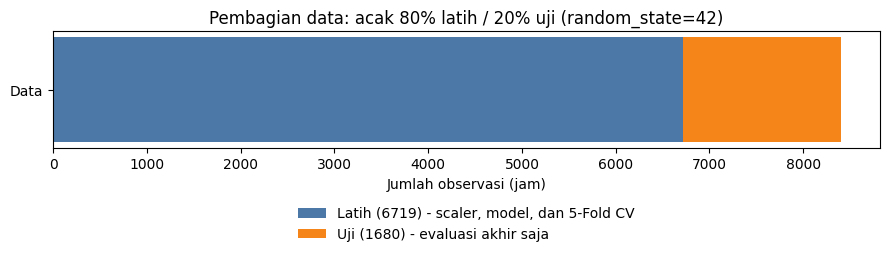

In [ ]:
import matplotlib.pyplot as plt

n_total, n_latih, n_uji = len(hourly), len(X_train), len(X_test)
print(f"Total observasi (jam): {n_total}")
print(f"Data latih: {n_latih} ({n_latih/n_total:.0%}) | Data uji: {n_uji} ({n_uji/n_total:.0%})")
print("Indeks latih dan uji saling lepas (tidak ada tumpang tindih):", len(set(X_train.index) & set(X_test.index)) == 0)
print("Scaler dilatih pada data latih (rata-rata terstandar data latih = 0):", bool(np.allclose(X_train_s.mean(), 0, atol=1e-9)))
print("Rata-rata terstandar data uji tidak tepat 0 (tidak ikut melatih scaler), maksimum |rata-rata|:", round(float(X_test_s.mean().abs().max()), 3))


fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(["Data"], [n_latih], color="#4C78A8", label=f"Latih ({n_latih}) - scaler, model, dan 5-Fold CV")
ax.barh(["Data"], [n_uji], left=[n_latih], color="#F58518", label=f"Uji ({n_uji}) - evaluasi akhir saja")
ax.set_xlabel("Jumlah observasi (jam)")
ax.set_title("Pembagian data: acak 80% latih / 20% uji (random_state=42)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=1, frameon=False)
plt.tight_layout()
plt.show()

# J. Audit Strategi Validasi

## Strategi yang Digunakan
Pembagian acak 80% data latih (6.719 jam) dan 20% data uji (1.680 jam) dengan random_state = 42. Pada tahap berikutnya, kestabilan model diuji dengan 5-Fold Cross-Validation pada data latih, sedangkan data uji disimpan untuk evaluasi akhir. Diagram pembagian data ada pada output sel kode di atas.

## Hasil Audit
1. **Bagaimana data dibagi menjadi training dan testing?** Secara acak 80/20. Indeks data latih dan data uji saling lepas (tidak ada observasi yang muncul di keduanya).
2. **Apakah validation set diperlukan untuk tuning?** Project ini unsupervised dan belum melakukan tuning hyperparameter. Ketika jumlah cluster dipilih secara sistematis nanti, pemilihan dilakukan dengan Cross-Validation pada data latih sebagai pengganti validation set terpisah, sehingga data uji tidak terpakai untuk memilih.
3. **Apakah pembagian sesuai jenis masalah?** Karena tidak ada target, stratifikasi tidak diperlukan dan pembagian acak biasa dipakai. Catatan keterbatasan: data berupa deret waktu per jam, sehingga jam yang berdekatan bisa terpisah ke data latih dan data uji. Hal ini dapat membuat hasil data uji tampak lebih mirip data latih daripada kondisi sebenarnya. Pembagian berdasarkan blok waktu dapat dipertimbangkan pada tahap berikutnya.
4. **Apakah preprocessing dipelajari hanya dari data latih?** Ya. StandardScaler dilatih (fit) hanya pada data latih, lalu diterapkan ke data uji. Langkah pembersihan lain (membuang kolom kembar, merekonstruksi waktu, agregasi per jam, dan fitur waktu) bekerja per baris atau per jam dan tidak mempelajari parameter dari data, sehingga tidak menimbulkan kebocoran data.
5. **Apakah data test sudah digunakan berulang kali untuk memilih model?** Tidak. Data uji hanya dipakai untuk menghitung metrik pelaporan dan belum digunakan untuk memilih model final atau parameter. Pemilihan akan dilakukan dengan Cross-Validation pada data latih.

## Alasan Pemilihan Strategi
Pembagian hold-out 80/20 sederhana dan cukup untuk data 8.399 observasi, sedangkan Cross-Validation pada data latih memberi gambaran kestabilan yang tidak bergantung pada satu pembagian tunggal.

In [ ]:
from sklearn.model_selection import KFold
from sklearn.neighbors import NearestCentroid

def buat_model(nama, k):-
    if nama == "K-Means":
        return KMeans(n_clusters=k, n_init=10, random_state=42)
    if nama == "GMM":
        return GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42)
    return AgglomerativeClustering(n_clusters=k, linkage="ward")

def label_fold(nama, model, A, B):
    """Latih pada A, beri label B. Agglomerative: B diberi label centroid terdekat."""
    if nama == "Agglomerative":
        lab_a = model.fit_predict(A)
        return NearestCentroid().fit(A, lab_a).predict(B)
    model.fit(A)
    return model.predict(B)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
hasil_cv = []
for nomor, (idx_a, idx_b) in enumerate(kf.split(X_train), start=1):
    A_raw, B_raw = X_train.iloc[idx_a], X_train.iloc[idx_b]
    sc = StandardScaler().fit(A_raw)               # scaler hanya dari bagian latih fold
    A, B = sc.transform(A_raw), sc.transform(B_raw)
    for nama in ["K-Means", "GMM", "Agglomerative"]:
        for k in [2, 3]:
            lab = label_fold(nama, buat_model(nama, k), A, B)
            hasil_cv.append({"Fold": nomor, "Model": nama, "k": k,
                             "Silhouette": silhouette_score(B, lab),
                             "Davies-Bouldin": davies_bouldin_score(B, lab),
                             "Calinski-Harabasz": calinski_harabasz_score(B, lab)})

cv = pd.DataFrame(hasil_cv)


sil = cv.pivot_table(index="Fold", columns=["Model", "k"], values="Silhouette")
tabel_fold = sil.round(3)
tabel_fold.loc["Rata-rata"] = sil.mean().round(3)
tabel_fold.loc["Std"] = sil.std().round(3)
display(tabel_fold)


ringkas = cv.groupby(["Model", "k"])[["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]].agg(["mean", "std"]).round(3)
display(ringkas)

Model     Agglomerative           GMM        K-Means       
k                     2      3      2      3       2      3
Fold                                                       
1                 0.155  0.154  0.084  0.097   0.103  0.102
2                 0.135  0.125  0.076  0.069   0.101  0.101
3                 0.181  0.103  0.107  0.033   0.090  0.092
4                 0.192  0.134  0.121  0.067   0.098  0.096
5                 0.179  0.176  0.112 -0.012   0.107  0.104
Rata-rata         0.169  0.138  0.100  0.051   0.100  0.099
Std               0.023  0.028  0.019  0.042   0.006  0.005

Silhouette        Davies-Bouldin        Calinski-Harabasz  \
                      mean    std           mean    std              mean   
Model         k                                                             
Agglomerative 2      0.169  0.023          3.397  0.518            86.855   
              3      0.138  0.028          2.997  0.249            82.714   
GMM           2      0.100  0.019          4.319  0.175            64.406   
              3      0.051  0.042          4.270  0.343            51.886   
K-Means       2      0.100  0.006          3.302  0.057            99.055   
              3      0.099  0.005          2.806  0.033            98.011   

                         
                    std  
Model         k          
Agglomerative 2  11.933  
              3   7.521  
GMM           2   4.988  
              3   5.127  
K-Means       2   3.447  
              3   3.772

# K. Uji Kestabilan Model (5-Fold Cross-Validation)

## Metode
- KFold 5 lipatan (shuffle = True, random_state = 42) pada data latih (6.719 jam)
- Pada setiap fold, StandardScaler dan model dilatih hanya pada 4 lipatan latih. Lipatan ke-5 diberi label dan dinilai, sehingga tidak ada kebocoran data antar fold
- Karena project ini clustering (tanpa target), yang diukur adalah kestabilan metrik internal antar fold, bukan akurasi
- Agglomerative tidak punya fungsi prediksi, sehingga lipatan validasi diberi label centroid terdekat dari lipatan latih

## Hasil (rata-rata ± simpangan baku antar 5 fold)
| Model         | k | Silhouette      | Davies-Bouldin  | Calinski-Harabasz |
|---------------|---|-----------------|-----------------|-------------------|
| K-Means       | 2 | 0,100 ± 0,006   | 3,302 ± 0,057   | 99,1 ± 3,4        |
| K-Means       | 3 | 0,099 ± 0,005   | 2,806 ± 0,033   | 98,0 ± 3,8        |
| GMM           | 2 | 0,100 ± 0,019   | 4,319 ± 0,175   | 64,4 ± 5,0        |
| GMM           | 3 | 0,051 ± 0,042   | 4,270 ± 0,343   | 51,9 ± 5,1        |
| Agglomerative | 2 | 0,169 ± 0,023   | 3,397 ± 0,518   | 86,9 ± 11,9       |
| Agglomerative | 3 | 0,138 ± 0,028   | 2,997 ± 0,249   | 82,7 ± 7,5        |

Skor Silhouette tiap fold ada pada tabel output sel kode di atas.

## Interpretasi Kestabilan
- **K-Means paling stabil.** Simpangan baku Silhouette hanya 0,005 sampai 0,006, jadi hasilnya hampir sama di semua fold.
- **GMM kurang stabil, terutama pada k=3.** Silhouette rata-rata hanya 0,051 dengan simpangan baku 0,042 dan satu fold bernilai negatif (sekitar -0,012), artinya pada fold tersebut cluster saling tumpang tindih. GMM dengan k=3 sebaiknya tidak diandalkan.
- **Agglomerative memiliki skor tertinggi tetapi variasinya lebih besar** (simpangan baku Silhouette 0,023 dan 0,028; Davies-Bouldin k=2 bervariasi 0,518). Nilai yang tinggi sebagian dapat berasal dari cara pelabelan fold lewat centroid terdekat, sehingga perlu dibandingkan dengan hati-hati.
- Secara umum, performa relatif stabil pada K-Means, cukup bervariasi pada Agglomerative, dan paling berubah-ubah pada GMM dengan k=3.
- Skor Silhouette semua model tetap rendah (di bawah sekitar 0,17), konsisten dengan temuan sebelumnya bahwa struktur cluster pada data ini belum tegas.

# L. Ensemble Learning dan Pemeriksaan Data Tidak Seimbang

## Ensemble Learning (Tugas 3)
Contoh kandidat ensemble pada materi adalah Random Forest, Gradient Boosting, dan XGBoost atau LightGBM. Ketiganya adalah model terawasi yang dilatih untuk memprediksi target (label), sedangkan project ini adalah unsupervised learning (clustering) tanpa target. Karena itu ensemble jenis tersebut **tidak relevan** dan tidak dijalankan pada project ini.

Perbandingan antar model yang dilakukan pada bagian H menunjukkan bahwa K-Means, GMM, dan Agglomerative menghasilkan pengelompokan yang sangat berbeda (ARI mendekati 0 pada k=2). Hal ini menjadi catatan bahwa menggabungkan hasil model secara langsung tidak sederhana dan belum dicoba pada tahap ini.

## Data Tidak Seimbang (Tugas 4)
Pemeriksaan distribusi kelas, confusion matrix, dan penanganan ketidakseimbangan hanya berlaku untuk project klasifikasi. Project ini tidak memiliki kelas target, sehingga **tugas ini tidak berlaku**.

Sebagai pengamatan yang terkait, ukuran cluster hasil model tidak merata. Contohnya Agglomerative k=2 menghasilkan cluster 5.887 dan 832 jam pada data latih, sementara K-Means k=2 menghasilkan 2.343 dan 4.376 jam. Ini bukan ketidakseimbangan kelas, melainkan karakteristik hasil clustering yang perlu diperhatikan saat menafsirkan cluster kecil.

# M. Interpretasi Hasil, Keterbatasan, dan Rencana Pertemuan 6-7

## Interpretasi Hasil Pertemuan 5
- **Kestabilan:** K-Means paling stabil antar fold (simpangan baku Silhouette 0,005 sampai 0,006). GMM dengan k=3 paling tidak stabil (Silhouette 0,051 ± 0,042, satu fold bernilai negatif), sehingga kurang layak diandalkan. Agglomerative memiliki skor tertinggi (0,169 pada k=2) tetapi variasi antar fold lebih besar.
- **Manfaat kandidat dibanding baseline:** tidak ada model yang unggul pada semua metrik. Agglomerative unggul pada Silhouette, K-Means unggul pada Calinski-Harabasz dan kestabilan, dan GMM menemukan pola yang berbeda (jam aktif dan jam sepi). Kandidat memberi sudut pandang baru, tetapi belum ada bukti satu model jelas lebih baik.
- **Makna terhadap masalah:** pola penggunaan perangkat paling jelas muncul pada GMM, sedangkan K-Means dan Agglomerative lebih banyak dibentuk oleh cuaca dan musim.
- **Keputusan sementara:** model final belum diputuskan. Keputusan akan didasarkan pada bukti dari pemilihan jumlah cluster, uji dengan dan tanpa fitur cuaca, dan kestabilan pada tahap berikutnya.

## Keterbatasan Eksperimen
1. Semua nilai Silhouette rendah (di bawah sekitar 0,17), sehingga struktur cluster belum tegas.
2. Data berupa deret waktu per jam, tetapi pembagian dan Cross-Validation dilakukan secara acak, sehingga jam yang berdekatan dapat terpisah antara data latih dan data uji. Hasil bisa tampak lebih baik daripada kondisi sebenarnya.
3. Agglomerative tidak punya fungsi prediksi, sehingga data uji dan lipatan validasi diberi label centroid terdekat. Hasilnya tidak sepenuhnya sebanding dengan K-Means dan GMM.
4. Hanya k = 2 dan k = 3 yang dicoba, sedangkan BIC pada GMM menurun tajam dari k=2 ke k=3 sehingga jumlah cluster yang lebih besar belum dieksplorasi.
5. Interval waktu 1 baris = 1 menit dan zona waktu UTC-5 adalah asumsi dari pola data, bukan keterangan resmi dataset.
6. Tidak ada label kebenaran, sehingga kualitas cluster hanya dinilai dengan metrik internal dan interpretasi manual.

## Rencana Eksperimen Pertemuan 6 dan 7
**Pertemuan 6 (pengembangan unsupervised learning dan reduksi dimensi):**
- Memilih jumlah cluster secara sistematis (k = 2 sampai 8) dengan Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz, serta BIC dan AIC untuk GMM.
- Menerapkan PCA untuk reduksi dimensi dan membandingkan hasil dengan dan tanpa PCA di dalam Pipeline.
- Membuat tabel ukuran dan profil cluster, serta mempertimbangkan algoritma alternatif seperti DBSCAN.

**Pertemuan 7 (seleksi fitur, diagnosis, dan analisis error):**
- Membandingkan clustering dengan dan tanpa fitur cuaca, serta dengan fitur yang dipilih (misalnya membuang fitur bervarians sangat kecil).
- Mendiagnosis jam yang berada di batas antar cluster (nilai Silhouette individual negatif) dan cluster kecil (misalnya 99 jam pada K-Means k=5 dan 832 jam pada Agglomerative).
- Memeriksa nilai ekstrem pada konsumsi perangkat (misalnya Barn dengan maksimum sekitar 7 kW dan rata-rata sekitar 0,06 kW) dan pengaruhnya terhadap cluster.

,Inertia (K-Means),Silhouette,Davies-Bouldin,Calinski-Harabasz,BIC (GMM),AIC (GMM)
k,,,,,,
2,137647.921,0.101,3.317,496.294,207234.788,203480.993
3,129014.518,0.099,2.810,489.419,109699.280,104065.181
4,122673.934,0.089,2.550,458.787,47886.706,40372.303
5,116747.771,0.098,2.235,446.702,38977.142,29582.436
6,111302.171,0.107,2.114,440.478,26419.721,15144.712
7,106472.969,0.109,2.010,434.395,25151.402,11996.088
8,102303.283,0.115,1.905,426.532,23012.418,7976.801


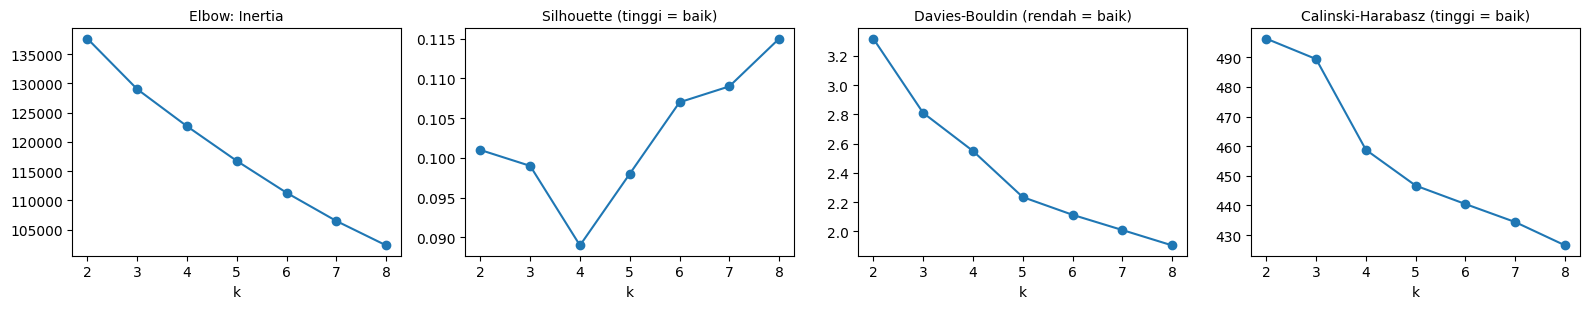

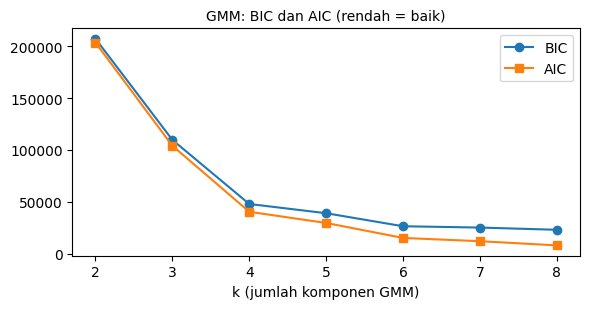

In [ ]:
import matplotlib.pyplot as plt

daftar_k = list(range(2, 9))
baris = []
for k in daftar_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_train_s)
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42).fit(X_train_s)
    baris.append({"k": k,
                  "Inertia (K-Means)": km.inertia_,
                  "Silhouette": silhouette_score(X_train_s, km.labels_),
                  "Davies-Bouldin": davies_bouldin_score(X_train_s, km.labels_),
                  "Calinski-Harabasz": calinski_harabasz_score(X_train_s, km.labels_),
                  "BIC (GMM)": gm.bic(X_train_s),
                  "AIC (GMM)": gm.aic(X_train_s)})
pilih_k = pd.DataFrame(baris).set_index("k").round(3)
display(pilih_k)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, kol, judul in zip(ax, ["Inertia (K-Means)", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                         ["Elbow: Inertia", "Silhouette (tinggi = baik)", "Davies-Bouldin (rendah = baik)", "Calinski-Harabasz (tinggi = baik)"]):
    a.plot(pilih_k.index, pilih_k[kol], marker="o")
    a.set_title(judul, fontsize=10); a.set_xlabel("k")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(pilih_k.index, pilih_k["BIC (GMM)"], marker="o", label="BIC")
ax.plot(pilih_k.index, pilih_k["AIC (GMM)"], marker="s", label="AIC")
ax.set_xlabel("k (jumlah komponen GMM)"); ax.set_title("GMM: BIC dan AIC (rendah = baik)", fontsize=10)
ax.legend(); plt.tight_layout(); plt.show()

# N. Pemilihan Jumlah Cluster

## Metode
Jumlah cluster k = 2 sampai 8 diuji pada data latih yang sudah distandardisasi (6.719 jam). Untuk K-Means dihitung Inertia (untuk Elbow), Silhouette, Davies-Bouldin, dan Calinski-Harabasz. Untuk GMM dihitung BIC dan AIC. Semua nilai dihitung pada ruang fitur yang sama sehingga dapat dibandingkan antar k.

## Hasil
| k | Inertia   | Silhouette | Davies-Bouldin | Calinski-Harabasz | BIC (GMM) | AIC (GMM) |
|---|-----------|------------|----------------|-------------------|-----------|-----------|
| 2 | 137.647,9 | 0,101      | 3,317          | 496,3             | 207.234,8 | 203.481,0 |
| 3 | 129.014,5 | 0,099      | 2,810          | 489,4             | 109.699,3 | 104.065,2 |
| 4 | 122.673,9 | 0,089      | 2,550          | 458,8             | 47.886,7  | 40.372,3  |
| 5 | 116.747,8 | 0,098      | 2,235          | 446,7             | 38.977,1  | 29.582,4  |
| 6 | 111.302,2 | 0,107      | 2,114          | 440,5             | 26.419,7  | 15.144,7  |
| 7 | 106.473,0 | 0,109      | 2,010          | 434,4             | 25.151,4  | 11.996,1  |
| 8 | 102.303,3 | 0,115      | 1,905          | 426,5             | 23.012,4  | 7.976,8   |

Grafik Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz, serta BIC dan AIC ada pada output sel kode di atas.

## Interpretasi
- **Elbow:** Inertia turun halus dari 137.648 (k=2) ke 102.303 (k=8) tanpa tekukan yang jelas, sehingga Elbow tidak menunjukkan satu k yang tegas.
- **Silhouette:** semua nilai rendah (0,089 sampai 0,115). Nilai tertinggi ada pada k=8 (0,115), tetapi selisihnya dengan k=2 (0,101) sangat kecil, sehingga tidak cukup kuat untuk menyimpulkan bahwa k=8 lebih baik.
- **Davies-Bouldin** membaik terus sampai k=8 (1,905), sedangkan **Calinski-Harabasz** tertinggi pada k=2 (496,3) dan terus turun. Kedua metrik ini berlawanan arah.
- **BIC dan AIC GMM** turun terus sampai k=8 tanpa titik minimum. Hal ini menunjukkan model yang lebih kompleks selalu lebih cocok dengan data, dan bisa berarti komponen tambahan menangkap lonjakan atau nilai ekstrem, bukan kelompok yang bermakna. Perlu diperiksa lewat profil cluster.
- **Kesimpulan:** metrik tidak sepakat dan tidak ada satu k yang jelas terbaik. Klaim "k terbaik" tidak dibuat dari satu metrik saja.

## Keputusan Sementara
k = 2 dan k = 3 tetap menjadi fokus karena paling mudah diinterpretasi. k yang lebih besar (misalnya 5 sampai 8) diperiksa melalui profil dan ukuran cluster pada bagian berikutnya sebelum diputuskan.

In [ ]:
def tabel_profil(labels):
    """Ukuran dan rata-rata nilai asli tiap cluster (data latih). Cluster diberi nomor urut dari yang terbesar."""
    urut = pd.Series(labels).value_counts().index
    peta = {lama: baru for baru, lama in enumerate(urut)}
    d = (X_train.drop(columns=["hour_sin", "hour_cos"])
         .assign(cluster=[peta[l] for l in labels], jam=X_train.index.hour, bulan=X_train.index.month))
    ukuran = d["cluster"].value_counts().sort_index()
    profil = d.groupby("cluster").mean()
    profil.insert(0, "Persen (%)", (ukuran / len(d) * 100).round(1))
    profil.insert(0, "Ukuran (jam)", ukuran)
    return profil.round(3)

for k in [3, 5]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_train_s)
    print(f"Profil cluster K-Means k={k} (Silhouette = {silhouette_score(X_train_s, km.labels_):.3f})")
    display(tabel_profil(km.labels_).T)

Profil cluster K-Means k=3 (Silhouette = 0.099)


cluster,0,1,2
Ukuran (jam),3748.000,1953.000,1018.000
Persen (%),55.800,29.100,15.200
Dishwasher [kW],0.031,0.029,0.039
Furnace 1 [kW],0.042,0.209,0.102
Furnace 2 [kW],0.083,0.241,0.132
Home office [kW],0.089,0.074,0.073
Fridge [kW],0.071,0.050,0.060
Wine cellar [kW],0.055,0.022,0.035
Garage door [kW],0.014,0.014,0.014
Kitchen 12 [kW],0.003,0.003,0.002


Profil cluster K-Means k=5 (Silhouette = 0.098)


cluster,0,1,2,3,4
Ukuran (jam),3306.000,1573.000,920.000,821.000,99.000
Persen (%),49.200,23.400,13.700,12.200,1.500
Dishwasher [kW],0.030,0.020,0.038,0.050,0.053
Furnace 1 [kW],0.040,0.215,0.099,0.117,0.102
Furnace 2 [kW],0.083,0.252,0.131,0.139,0.119
Home office [kW],0.091,0.070,0.075,0.079,0.080
Fridge [kW],0.069,0.047,0.060,0.076,0.072
Wine cellar [kW],0.053,0.020,0.034,0.046,0.060
Garage door [kW],0.014,0.014,0.014,0.015,0.014
Kitchen 12 [kW],0.001,0.001,0.001,0.002,0.125


# O. Tabel Ukuran dan Profil Cluster

## K-Means k = 3 (Silhouette 0,099)
| Cluster | Ukuran (jam) | Persen | Furnace 1 + 2 (kW) | Suhu (F) | Awan | Kelembapan | Bulan rata-rata |
|---------|--------------|--------|--------------------|----------|------|------------|-----------------|
| 0       | 3.748        | 55,8%  | 0,042 + 0,083      | 60,8     | 0,14 | 0,65       | 7,0             |
| 1       | 1.953        | 29,1%  | 0,209 + 0,241      | 33,7     | 0,13 | 0,59       | 4,7             |
| 2       | 1.018        | 15,2%  | 0,102 + 0,132      | 46,4     | 0,73 | 0,87       | 6,7             |

- **Cluster 0:** jam hangat dengan pemanas rendah dan cuaca cerah.
- **Cluster 1:** jam dingin dengan pemanas tinggi, cenderung terjadi di awal tahun.
- **Cluster 2:** jam berawan dan lembap dengan suhu sedang.
- Aktivitas perangkat rumah (Living room, Kitchen, Well, Microwave) hampir tidak berbeda antar cluster, sehingga pembagian ini terutama menggambarkan cuaca dan musim, bukan kebiasaan penggunaan perangkat.

## K-Means k = 5 (Silhouette 0,098)
| Cluster | Ukuran (jam) | Persen | Ciri utama |
|---------|--------------|--------|------------|
| 0       | 3.306        | 49,2%  | Hangat (60,7 F), pemanas dan perangkat rendah: jam sepi |
| 1       | 1.573        | 23,4%  | Dingin (33,4 F), Furnace 0,215 dan 0,252 kW: jam pemanas tinggi, rata-rata bulan 4,5 |
| 2       | 920          | 13,7%  | Berawan (awan 0,75, kelembapan 0,87, jarak pandang 6,4) |
| 3       | 821          | 12,2%  | Perangkat aktif: Living room 0,189 kW, Well 0,058, Microwave 0,040, Kitchen 14 0,038 |
| 4       | 99           | 1,5%   | Kitchen 12 aktif (0,125 kW dibanding 0,001 sampai 0,002 pada cluster lain) |

## Interpretasi
- Pada k=5, tiga pola dari model yang berbeda muncul dalam satu pembagian: cuaca berawan, pemanas dan musim dingin, serta jam dengan perangkat aktif, ditambah satu cluster kecil.
- Nilai Silhouette k=5 (0,098) hampir sama dengan k=3 (0,099). Metrik tidak menunjukkan k=5 lebih baik, tetapi hasilnya lebih kaya untuk ditafsirkan terhadap tujuan project (pola penggunaan perangkat).
- Cluster 4 hanya 99 jam (1,5%) dan ditandai penggunaan Kitchen 12 yang tidak biasa. Ini kemungkinan kejadian khusus atau nilai ekstrem, perlu diperiksa lebih lanjut sebelum dianggap sebagai pola penggunaan yang berulang.
- Klaim bahwa satu k lebih baik tidak dibuat dari satu metrik. Pemilihan akhir mempertimbangkan metrik, kestabilan, dan interpretabilitas.

,Explained variance,Varians kumulatif
Komponen,,
1,0.099,0.099
2,0.096,0.195
3,0.084,0.279
4,0.065,0.344
5,0.065,0.409
6,0.061,0.470
7,0.049,0.519
8,0.047,0.566
9,0.046,0.612


Komponen untuk varians kumulatif >= 80%: 14 dari 22 fitur
Komponen untuk varians kumulatif >= 90%: 18 dari 22 fitur
Komponen untuk varians kumulatif >= 95%: 20 dari 22 fitur


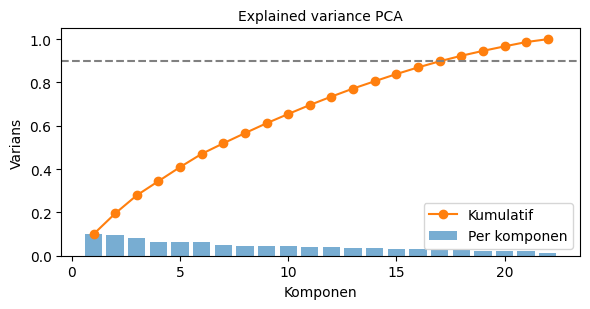

,Skenario,k,Dimensi,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs tanpa PCA
0,Tanpa PCA (22 fitur),3,22,0.099,2.810,489.419,1.000
1,PCA 18 komponen,3,18,0.099,2.811,489.168,0.980
2,PCA 14 komponen,3,14,0.098,2.817,487.827,0.949
3,Tanpa PCA (22 fitur),5,22,0.098,2.235,446.702,1.000
4,PCA 18 komponen,5,18,0.098,2.234,446.558,0.981
5,PCA 14 komponen,5,14,0.097,2.242,444.947,0.925


In [ ]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt


pca_penuh = PCA(random_state=42).fit(X_train_s)
evr = pca_penuh.explained_variance_ratio_
kum = np.cumsum(evr)
tabel_pca = pd.DataFrame({"Komponen": range(1, len(evr) + 1),
                          "Explained variance": evr.round(3),
                          "Varians kumulatif": kum.round(3)}).set_index("Komponen")
display(tabel_pca)
for target in [0.80, 0.90, 0.95]:
    print(f"Komponen untuk varians kumulatif >= {target:.0%}: {int(np.argmax(kum >= target)) + 1} dari {len(evr)} fitur")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(1, len(evr) + 1), evr, alpha=0.6, label="Per komponen")
ax.plot(range(1, len(evr) + 1), kum, marker="o", color="C1", label="Kumulatif")
ax.axhline(0.90, ls="--", color="gray"); ax.set_xlabel("Komponen"); ax.set_ylabel("Varians")
ax.set_title("Explained variance PCA", fontsize=10); ax.legend(); plt.tight_layout(); plt.show()


hasil = []
for k in [3, 5]:
    ref = Pipeline([("scaler", StandardScaler()),
                    ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=42))]).fit(X_train)
    lab_ref = ref.predict(X_train)
    hasil.append({"Skenario": "Tanpa PCA (22 fitur)", "k": k, "Dimensi": 22,
                  "Silhouette": silhouette_score(X_train_s, lab_ref),
                  "Davies-Bouldin": davies_bouldin_score(X_train_s, lab_ref),
                  "Calinski-Harabasz": calinski_harabasz_score(X_train_s, lab_ref),
                  "ARI vs tanpa PCA": 1.0})
    for n_komp in [14, 18]:
        pipa = Pipeline([("scaler", StandardScaler()),
                         ("pca", PCA(n_components=n_komp, random_state=42)),
                         ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=42))]).fit(X_train)
        lab = pipa.predict(X_train)
        pipa.predict(X_test)
        hasil.append({"Skenario": f"PCA {n_komp} komponen", "k": k, "Dimensi": n_komp,
                      "Silhouette": silhouette_score(X_train_s, lab),
                      "Davies-Bouldin": davies_bouldin_score(X_train_s, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(X_train_s, lab),
                      "ARI vs tanpa PCA": adjusted_rand_score(lab_ref, lab)})

banding_pca = pd.DataFrame(hasil).sort_values(["k", "Dimensi"], ascending=[True, False]).round(3)
display(banding_pca.reset_index(drop=True))

# P. PCA (Principal Component Analysis)

## Alasan PCA Dipertimbangkan
Data memiliki 22 fitur yang sebagian saling berkorelasi (perangkat, cuaca, dan waktu). PCA diuji untuk melihat apakah dimensi dapat dikurangi tanpa banyak mengubah hasil clustering, dan bukan diterapkan secara otomatis.

## Explained Variance
- Komponen pertama hanya menjelaskan 9,9% varians dan komponen kedua 9,6% (kumulatif 19,5%). Varians tersebar cukup merata di banyak komponen.
- Untuk mempertahankan 80%, 90%, dan 95% varians dibutuhkan 14, 18, dan 20 komponen dari 22 fitur.
- Artinya data tidak memiliki struktur dimensi rendah yang kuat. Pengurangan dimensi yang berarti hanya mungkin dengan kehilangan varians yang cukup besar.

## Perbandingan Dengan dan Tanpa PCA
Scaling dan PCA ditempatkan di dalam Pipeline (StandardScaler, PCA, K-Means) dan dilatih hanya pada data latih, sehingga data uji tidak memengaruhi scaler maupun PCA. Seluruh skenario dinilai pada ruang fitur yang sama (22 fitur terstandar) agar metrik dapat dibandingkan.

| Skenario             | k | Dimensi | Silhouette | Davies-Bouldin | Calinski-Harabasz | ARI vs tanpa PCA |
|----------------------|---|---------|------------|----------------|-------------------|------------------|
| Tanpa PCA            | 3 | 22      | 0,099      | 2,810          | 489,4             | 1,000            |
| PCA 18 komponen      | 3 | 18      | 0,099      | 2,811          | 489,2             | 0,980            |
| PCA 14 komponen      | 3 | 14      | 0,098      | 2,817          | 487,8             | 0,949            |
| Tanpa PCA            | 5 | 22      | 0,098      | 2,235          | 446,7             | 1,000            |
| PCA 18 komponen      | 5 | 18      | 0,098      | 2,234          | 446,6             | 0,981            |
| PCA 14 komponen      | 5 | 14      | 0,097      | 2,242          | 444,9             | 0,925            |

## Interpretasi dan Trade-off
- Hasil clustering dengan PCA 14 sampai 18 komponen hampir sama dengan tanpa PCA (metrik hampir identik, ARI 0,925 sampai 0,981). PCA tidak memperbaiki hasil, hanya sedikit mengurangi dimensi.
- Karena PCA tidak meningkatkan kualitas dan hanya mengurangi dimensi dari 22 menjadi 14 sampai 18, manfaatnya terbatas pada dataset ini. Sementara itu, komponen PCA adalah kombinasi fitur sehingga lebih sulit diinterpretasi dibanding fitur asli (misalnya "Living room" atau "suhu"), padahal interpretasi cluster adalah tujuan utama project.
- Keputusan sementara: PCA tidak digunakan untuk model utama. PCA hanya relevan untuk visualisasi dua dimensi, dengan catatan dua komponen pertama hanya mewakili sekitar 19,5% varians sehingga gambar dua dimensi tidak menggambarkan seluruh struktur data.
- Perbandingan ini belum cukup untuk menyimpulkan bahwa tanpa PCA selalu lebih baik. Kesimpulan hanya berlaku untuk dua jumlah cluster (k=3 dan k=5) dan dua jumlah komponen (14 dan 18) yang diuji.

In [ ]:
import sys, sklearn, matplotlib

print("Python       :", sys.version.split()[0])
print("pandas       :", pd.__version__)
print("numpy        :", np.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)
print("random_state yang dipakai: 42 (pembagian data, K-Means, GMM, PCA, KFold)")

Python       : 3.13.18
pandas       : 2.2.3
numpy        : 2.1.3
scikit-learn : 1.6.1
matplotlib   : 3.10.0
random_state yang dipakai: 42 (pembagian data, K-Means, GMM, PCA, KFold)


# Q. Catatan Eksperimen dan Keputusan Metodologis

## Catatan Parameter, Random Seed, dan Metrik
| Komponen | Pengaturan |
|----------|------------|
| Dataset | Smart Home Dataset with Weather Information (Kaggle, taranvee), file HomeC.csv |
| Unit observasi | Satu jam (rata-rata dari data per menit), 8.399 observasi |
| Fitur | 22: 13 perangkat, 6 cuaca, 3 waktu (hour_sin, hour_cos, weekend) |
| Pembagian data | Acak 80% latih (6.719) dan 20% uji (1.680), random_state = 42 |
| Scaling | StandardScaler, dilatih hanya pada data latih (di dalam Pipeline atau di dalam tiap fold) |
| K-Means | n_init = 10, random_state = 42, k = 2 sampai 8 |
| GMM | covariance_type = full, n_init = 5, random_state = 42, k = 2 sampai 8 |
| Agglomerative | linkage = ward, k = 2 dan 3, label data uji lewat centroid terdekat |
| PCA | 14 dan 18 komponen, random_state = 42, di dalam Pipeline |
| Validasi | Hold-out 80/20 dan 5-Fold Cross-Validation (shuffle = True, random_state = 42) pada data latih |
| Metrik | Silhouette, Davies-Bouldin, Calinski-Harabasz, BIC dan AIC (GMM), ARI antar model |
| Versi library | Lihat output sel kode di atas |

Implementasi memakai scikit-learn [4]. Metrik evaluasi: Silhouette [5], Davies-Bouldin [6], dan Calinski-Harabasz [7]. Sumber dataset: Kaggle [3].

## Ringkasan Temuan dan Keputusan Metodologis
1. **Unit observasi per jam.** Data per menit (503.910 baris) terlalu besar untuk Agglomerative dan pola penggunaan perangkat lebih bermakna pada skala jam.
2. **Scaling wajib** karena K-Means, GMM, dan Agglomerative berbasis jarak atau varians. Scaler dilatih hanya pada data latih untuk mencegah kebocoran data.
3. **Tiga algoritma dibandingkan** tanpa menyatakan satu model terbaik. Setiap model menemukan pola berbeda (K-Means: musim dan pemanas; GMM: jam aktif dan jam sepi; Agglomerative: jam berawan dan jam aktif), dengan ARI mendekati 0 pada k=2. Tidak ada satu metrik yang unggul untuk semua model.
4. **Jumlah cluster belum final.** Metrik tidak sepakat (Calinski-Harabasz tertinggi pada k=2, Davies-Bouldin dan BIC terus membaik sampai k=8, Silhouette hampir datar). k=3 dipakai sebagai fokus interpretasi, dan k=5 memberi hasil yang lebih kaya (cuaca berawan, musim dingin, jam aktif, dan satu cluster kecil) tanpa penurunan Silhouette.
5. **PCA tidak dipakai di model utama.** Varians tersebar merata (14 komponen untuk 80%, 18 untuk 90%) dan hasil clustering hampir sama dengan tanpa PCA, sedangkan komponen PCA lebih sulit diinterpretasi.
6. **Validasi.** Hold-out 80/20 untuk pelaporan dan 5-Fold Cross-Validation untuk kestabilan. K-Means paling stabil, GMM dengan k=3 paling tidak stabil.
7. **Model final belum diputuskan.** Seleksi fitur (bagian R), diagnosis (S), dan analisis error (T) menunjukkan kandidat utama sementara adalah K-Means k=5 dengan fitur perangkat saja. Namun cluster jam aktif berbatas kabur dan Barn belum terwakili, sehingga keputusan akhir menunggu perbaikan lebih lanjut.

## Keterbatasan
- Silhouette semua model rendah (di bawah sekitar 0,17), sehingga struktur cluster belum tegas.
- Pembagian data dan Cross-Validation dilakukan secara acak pada data deret waktu, sehingga hasil dapat tampak lebih baik daripada kondisi sebenarnya.
- Label data uji dan fold untuk Agglomerative diperoleh lewat centroid terdekat, sehingga tidak sepenuhnya sebanding dengan model lain.
- Interval 1 baris = 1 menit dan zona waktu UTC-5 adalah asumsi dari pola data, bukan keterangan resmi dataset.
- DBSCAN belum diuji. Cluster kecil Kitchen 12 (99 jam) sudah diperiksa pada bagian T (tersebar pada 33 tanggal berbeda), tetapi penyebab penggunaan perangkat itu tidak dapat dipastikan dari data.
- Tidak ada label kebenaran, sehingga evaluasi hanya memakai metrik internal dan interpretasi manual.

In [ ]:
waktu = ["hour_sin", "hour_cos", "weekend"]
skenario = {
    "Semua fitur (22)":      perangkat + cuaca + waktu,
    "Tanpa cuaca (16)":      perangkat + waktu,
    "Tanpa waktu (19)":      perangkat + cuaca,
    "Hanya perangkat (13)":  perangkat,
}
ruang_eval = X_train_s[perangkat]

hasil = []
label_fs = {}
for k in [3, 5]:
    for nama, kolom in skenario.items():
        pipa = Pipeline([("scaler", StandardScaler()),
                         ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=42))]).fit(X_train[kolom])
        lab = pipa.predict(X_train[kolom])
        label_fs[(k, nama)] = lab
        hasil.append({"k": k, "Skenario": nama, "Jumlah fitur": len(kolom),
                      "Silhouette": silhouette_score(ruang_eval, lab),
                      "Davies-Bouldin": davies_bouldin_score(ruang_eval, lab),
                      "Calinski-Harabasz": calinski_harabasz_score(ruang_eval, lab),
                      "Ukuran cluster": sorted(np.bincount(lab), reverse=True)})

fs = pd.DataFrame(hasil)

fs["ARI vs semua fitur"] = [adjusted_rand_score(label_fs[(r.k, "Semua fitur (22)")], label_fs[(r.k, r.Skenario)]) for r in fs.itertuples()]
display(fs.round(3))


def profil_ringkas(labels, kolom_tampil):
    urut = pd.Series(labels).value_counts().index
    peta = {l: b for b, l in enumerate(urut)}
    d = X_train.assign(cluster=[peta[l] for l in labels])
    p = d.groupby("cluster")[kolom_tampil].mean()
    p.insert(0, "Ukuran", d["cluster"].value_counts().sort_index())
    return p.round(3)

tampil = ["Furnace 1 [kW]", "Furnace 2 [kW]", "Living room [kW]", "Kitchen 14 [kW]", "Well [kW]",
          "Microwave [kW]", "Kitchen 12 [kW]", "Dishwasher [kW]", "temperature", "cloudCover"]
for k in [3, 5]:
    print(f"Hanya perangkat, k={k}")
    display(profil_ringkas(label_fs[(k, "Hanya perangkat (13)")], tampil))

,k,Skenario,Jumlah fitur,Silhouette,Davies-Bouldin,Calinski-Harabasz,Ukuran cluster,ARI vs semua fitur
0,3,Semua fitur (22),22,0.036,5.795,260.310,"[3748, 1953, 1018]",1.000
1,3,Tanpa cuaca (16),16,0.171,2.113,717.409,"[4170, 1482, 1067]",0.351
2,3,Tanpa waktu (19),19,0.038,5.771,257.585,"[3677, 2027, 1015]",0.938
3,3,Hanya perangkat (13),13,0.177,2.060,722.891,"[4255, 1507, 957]",0.354
4,5,Semua fitur (22),22,0.061,3.655,477.644,"[3306, 1573, 920, 821, 99]",1.000
5,5,Tanpa cuaca (16),16,0.196,1.659,712.155,"[3966, 1372, 965, 317, 99]",0.513
6,5,Tanpa waktu (19),19,0.055,3.629,476.366,"[3255, 1676, 927, 762, 99]",0.910
7,5,Hanya perangkat (13),13,0.214,1.597,756.357,"[3969, 1434, 822, 395, 99]",0.491


Hanya perangkat, k=3


,Ukuran,Furnace 1 [kW],Furnace 2 [kW],Living room [kW],Kitchen 14 [kW],Well [kW],Microwave [kW],Kitchen 12 [kW],Dishwasher [kW],temperature,cloudCover
cluster,,,,,,,,,,,
0,4255,0.046,0.082,0.009,0.002,0.008,0.006,0.002,0.033,56.002,0.221
1,1507,0.240,0.290,0.017,0.003,0.011,0.006,0.002,0.015,37.026,0.234
2,957,0.115,0.136,0.182,0.037,0.057,0.041,0.006,0.051,49.031,0.223


Hanya perangkat, k=5


,Ukuran,Furnace 1 [kW],Furnace 2 [kW],Living room [kW],Kitchen 14 [kW],Well [kW],Microwave [kW],Kitchen 12 [kW],Dishwasher [kW],temperature,cloudCover
cluster,,,,,,,,,,,
0,3969,0.046,0.082,0.009,0.002,0.008,0.006,0.001,0.001,56.090,0.220
1,1434,0.241,0.293,0.016,0.003,0.011,0.006,0.001,0.003,37.102,0.236
2,822,0.111,0.138,0.192,0.039,0.054,0.043,0.002,0.005,49.119,0.234
3,395,0.097,0.116,0.037,0.008,0.029,0.009,0.001,0.489,49.738,0.232
4,99,0.102,0.119,0.062,0.008,0.033,0.017,0.125,0.053,52.106,0.121


# R. Seleksi Fitur (Pertemuan 7)

## Metode
K-Means (n_init = 10, random_state = 42, scaling di dalam Pipeline) dijalankan dengan empat kumpulan fitur: semua fitur (22), tanpa cuaca (16), tanpa waktu (19), dan hanya perangkat (13). Agar adil, semua hasil dinilai pada **ruang yang sama**, yaitu 13 fitur perangkat yang terstandar (Silhouette tidak boleh dibandingkan antar ruang fitur yang berbeda). Kemiripan antar skenario diukur dengan ARI terhadap hasil memakai semua fitur.

## Hasil
| k | Skenario        | Silhouette | Davies-Bouldin | Calinski-Harabasz | ARI vs semua fitur | Ukuran cluster (jam)           |
|---|-----------------|------------|----------------|-------------------|--------------------|--------------------------------|
| 3 | Semua fitur     | 0,036      | 5,795          | 260,3             | 1,000              | 3.748 / 1.953 / 1.018          |
| 3 | Tanpa cuaca     | 0,171      | 2,113          | 717,4             | 0,351              | 4.170 / 1.482 / 1.067          |
| 3 | Tanpa waktu     | 0,038      | 5,771          | 257,6             | 0,938              | 3.677 / 2.027 / 1.015          |
| 3 | Hanya perangkat | 0,177      | 2,060          | 722,9             | 0,354              | 4.255 / 1.507 / 957            |
| 5 | Semua fitur     | 0,061      | 3,655          | 477,6             | 1,000              | 3.306 / 1.573 / 920 / 821 / 99 |
| 5 | Tanpa cuaca     | 0,196      | 1,659          | 712,2             | 0,513              | 3.966 / 1.372 / 965 / 317 / 99 |
| 5 | Tanpa waktu     | 0,055      | 3,629          | 476,4             | 0,910              | 3.255 / 1.676 / 927 / 762 / 99 |
| 5 | Hanya perangkat | 0,214      | 1,597          | 756,4             | 0,491              | 3.969 / 1.434 / 822 / 395 / 99 |

## Interpretasi
- **Fitur cuaca mengubah pengelompokan secara besar.** Tanpa cuaca, ARI terhadap hasil semua fitur hanya sekitar 0,35 (k=3) dan 0,51 (k=5). Cluster "berawan dan lembap" yang muncul pada model semua fitur menghilang ketika cuaca dibuang.
- **Fitur waktu hampir tidak berpengaruh.** Tanpa waktu, ARI 0,938 (k=3) dan 0,910 (k=5), serta metrik hampir sama. Fitur jam dan akhir pekan kandidat untuk dibuang.
- **Cluster berbasis perangkat lebih jelas jika cuaca dibuang.** Pada skenario hanya perangkat (k=5) terbentuk lima kelompok yang mudah ditafsirkan: jam sepi (3.969 jam), jam pemanas tinggi (1.434 jam; Furnace 0,241 dan 0,293 kW, suhu rata-rata sekitar 37 derajat Fahrenheit), jam aktif ruang tamu dan dapur (822 jam; Living room 0,192 kW, Well 0,054, Microwave 0,043), jam Dishwasher aktif (395 jam; sekitar 0,489 kW), dan satu cluster kecil Kitchen 12 (99 jam).
- **Cluster Kitchen 12 (99 jam) muncul pada semua skenario k=5**, sehingga ini pola dari data perangkat, bukan akibat fitur cuaca.
- **Peringatan:** nilai Silhouette yang jauh lebih tinggi pada skenario tanpa cuaca (sekitar 0,17 sampai 0,21 dibanding 0,04 sampai 0,06) sebagian karena evaluasi dilakukan pada ruang perangkat, yaitu ruang yang juga dipakai skenario itu untuk membentuk cluster. Jadi angka ini tidak membuktikan bahwa tanpa cuaca "lebih baik" secara umum, hanya bahwa cuaca mengencerkan struktur berbasis perangkat.

## Keputusan Sementara
Fitur cuaca tidak dibuang dari analisis utama, tetapi tidak dibandingkan secara langsung dengan model berbasis perangkat. Untuk tujuan project (pola penggunaan perangkat), skenario hanya perangkat dengan k=5 dipertimbangkan sebagai kandidat utama pada tahap berikutnya. Fitur waktu menjadi kandidat untuk dibuang.

Semua fitur (22): rata-rata 0.098 | jam dengan Silhouette negatif: 964 dari 6719 (14.3%)
Hanya perangkat (13): rata-rata 0.214 | jam dengan Silhouette negatif: 706 dari 6719 (10.5%)


,cluster,Skenario,Ukuran,Rata-rata Silhouette,Jam bernilai negatif (%)
0,0,Semua fitur (22),3306,0.136,0.000
1,1,Semua fitur (22),1573,0.096,8.455
2,2,Semua fitur (22),920,0.075,20.435
3,3,Semua fitur (22),821,-0.058,77.954
4,4,Semua fitur (22),99,0.331,3.030
5,0,Hanya perangkat (13),3969,0.285,0.000
6,1,Hanya perangkat (13),1434,0.165,8.996
7,2,Hanya perangkat (13),822,-0.052,67.762
8,3,Hanya perangkat (13),395,0.177,4.557
9,4,Hanya perangkat (13),99,0.428,2.020


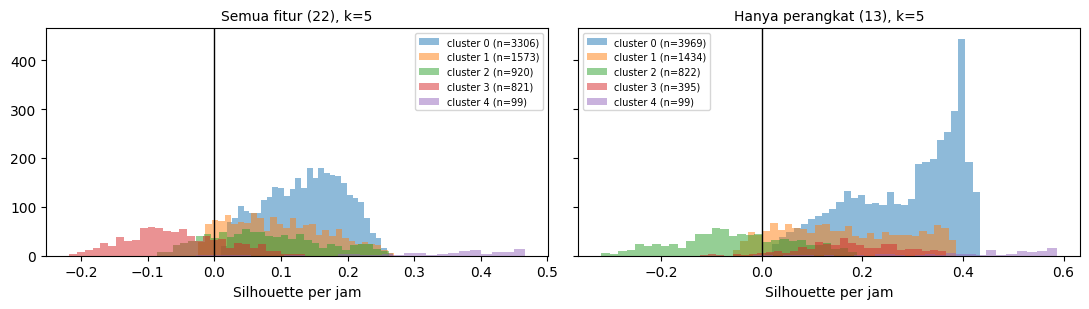

In [ ]:
from sklearn.metrics import silhouette_samples

ringkas_diag = []
diag = {}
for nama, kolom in [("Semua fitur (22)", perangkat + cuaca + waktu), ("Hanya perangkat (13)", perangkat)]:
    lab = label_fs[(5, nama)]
    Z = StandardScaler().fit(X_train[kolom]).transform(X_train[kolom])      # ruang model masing-masing
    s = silhouette_samples(Z, lab)
    urut = pd.Series(lab).value_counts().index
    peta = {l: b for b, l in enumerate(urut)}
    d = pd.DataFrame({"cluster": [peta[l] for l in lab], "silhouette": s}, index=X_train.index)
    diag[nama] = d
    g = d.groupby("cluster")["silhouette"]
    t = pd.DataFrame({"Skenario": nama, "Ukuran": g.size(), "Rata-rata Silhouette": g.mean(),
                      "Jam bernilai negatif (%)": g.apply(lambda x: (x < 0).mean() * 100)}).reset_index()
    ringkas_diag.append(t)
    print(f"{nama}: rata-rata {s.mean():.3f} | jam dengan Silhouette negatif: {(s < 0).sum()} dari {len(s)} ({(s < 0).mean():.1%})")

display(pd.concat(ringkas_diag, ignore_index=True).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, (nama, d) in zip(ax, diag.items()):
    for c, g in d.groupby("cluster"):
        a.hist(g["silhouette"], bins=30, alpha=0.5, label=f"cluster {c} (n={len(g)})")
    a.axvline(0, color="k", lw=1); a.set_title(nama + ", k=5", fontsize=10)
    a.set_xlabel("Silhouette per jam"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# S. Diagnosis: Silhouette per Jam

## Metode
Untuk K-Means k=5, Silhouette dihitung per jam (individual) pada ruang fitur masing-masing skenario. Nilai negatif berarti sebuah jam lebih dekat ke cluster lain daripada ke cluster-nya sendiri, sehingga berada di batas antar cluster. Karena ruang fitur berbeda, angka antar skenario tidak dibandingkan langsung.

## Hasil
| Skenario        | Cluster | Ukuran | Rata-rata Silhouette | Jam negatif (%) | Ciri utama |
|-----------------|---------|--------|----------------------|-----------------|------------|
| Semua fitur     | 0       | 3.306  | 0,136                | 0,0             | Jam hangat dan sepi |
| Semua fitur     | 1       | 1.573  | 0,096                | 8,5             | Jam dingin, pemanas tinggi |
| Semua fitur     | 2       | 920    | 0,075                | 20,4            | Jam berawan dan lembap |
| Semua fitur     | 3       | 821    | -0,058               | 78,0            | Jam dengan perangkat aktif |
| Semua fitur     | 4       | 99     | 0,331                | 3,0             | Kitchen 12 aktif |
| Hanya perangkat | 0       | 3.969  | 0,285                | 0,0             | Jam sepi |
| Hanya perangkat | 1       | 1.434  | 0,165                | 9,0             | Pemanas tinggi |
| Hanya perangkat | 2       | 822    | -0,052               | 67,8            | Jam aktif ruang tamu dan dapur |
| Hanya perangkat | 3       | 395    | 0,177                | 4,6             | Dishwasher aktif |
| Hanya perangkat | 4       | 99     | 0,428                | 2,0             | Kitchen 12 aktif |

Secara keseluruhan, 964 dari 6.719 jam (14,3%) bernilai negatif pada skenario semua fitur dan 706 jam (10,5%) pada skenario hanya perangkat.

## Interpretasi Diagnosis
- **Cluster jam aktif bermasalah pada kedua skenario.** Rata-rata Silhouette-nya negatif (-0,058 dan -0,052), dan sekitar 68% sampai 78% jamnya bernilai negatif. Artinya jam dengan perangkat aktif tidak membentuk kelompok yang terpisah jelas, tetapi lebih menyerupai kelanjutan dari jam sepi dan jam pemanas. K-Means memaksakan batas pada kelompok yang kabur.
- **Cluster Kitchen 12 (99 jam) paling rapat** (rata-rata 0,331 dan 0,428, hanya 2% sampai 3% negatif). Ini kelompok yang jelas terpisah, tetapi sangat kecil dan perlu diperiksa apakah pola berulang atau kejadian khusus.
- **Cluster jam sepi paling kuat** (tidak ada jam negatif) dan merupakan kelompok terbesar.
- **Cluster berawan (hanya pada semua fitur)** memiliki 20,4% jam negatif, lebih tidak tegas daripada jam sepi dan jam pemanas.
- Diagnosis ini menjelaskan mengapa Silhouette keseluruhan rendah: sumber utamanya adalah cluster jam aktif yang batasnya kabur, bukan semua cluster.

## Dugaan untuk Analisis Error
Jam aktif yang bernilai negatif perlu diperiksa pada bagian berikutnya (kapan terjadinya, dan perangkat mana yang membuatnya mirip dengan cluster lain).

Cluster 4: 99 jam | tanggal berbeda: 33 | bulan berbeda: 9
Jam berurutan (selisih tepat 1 jam): 58 dari 98
Jumlah jam per bulan: {1: 7, 2: 8, 5: 1, 7: 8, 8: 21, 9: 21, 10: 11, 11: 15, 12: 7}
Kitchen 12 pada cluster 4: rata-rata 0.125 kW, maksimum 0.205 kW


,Perangkat,Rata-rata,Maksimum,Distribusi cluster 20 jam tertinggi
0,Barn [kW],0.059,1.813,"{0: 13, 2: 4, 1: 3}"
1,Kitchen 12 [kW],0.003,0.205,{4: 20}
2,Dishwasher [kW],0.032,0.825,{3: 20}
3,Furnace 2 [kW],0.136,0.749,{1: 20}


Cluster jam aktif: 822 jam, bernilai negatif: 557 (67.8%)
Cluster tetangga terdekat dari jam negatif: {0: 396, 1: 157, 3: 3, 4: 1} (0 = jam sepi, 1 = pemanas tinggi)


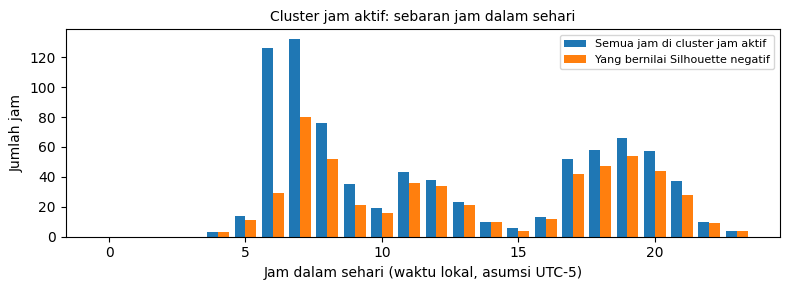

In [ ]:
d = diag["Hanya perangkat (13)"].copy()


k12 = d[d["cluster"] == 4].index.sort_values()
selisih_jam = pd.Series(k12).diff().dt.total_seconds().div(3600)
print(f"Cluster 4: {len(k12)} jam | tanggal berbeda: {len(set(k12.date))} | bulan berbeda: {k12.month.nunique()}")
print("Jam berurutan (selisih tepat 1 jam):", int((selisih_jam == 1).sum()), "dari", len(k12) - 1)
print("Jumlah jam per bulan:", pd.Series(k12.month).value_counts().sort_index().to_dict())
print("Kitchen 12 pada cluster 4: rata-rata", round(X_train.loc[k12, "Kitchen 12 [kW]"].mean(), 3), "kW, maksimum", round(X_train.loc[k12, "Kitchen 12 [kW]"].max(), 3), "kW")


baris = []
for kol in ["Barn [kW]", "Kitchen 12 [kW]", "Dishwasher [kW]", "Furnace 2 [kW]"]:
    top = X_train[kol].nlargest(20).index
    baris.append({"Perangkat": kol, "Rata-rata": X_train[kol].mean(), "Maksimum": X_train[kol].max(),
                  "Distribusi cluster 20 jam tertinggi": d.loc[top, "cluster"].value_counts().to_dict()})
display(pd.DataFrame(baris).round(3))


aktif = d[d["cluster"] == 2]
neg = aktif[aktif["silhouette"] < 0]
print(f"Cluster jam aktif: {len(aktif)} jam, bernilai negatif: {len(neg)} ({len(neg)/len(aktif):.1%})")

Z = StandardScaler().fit(X_train[perangkat]).transform(X_train[perangkat])
lab = d["cluster"].values
pusat = np.array([Z[lab == c].mean(axis=0) for c in range(5)])
jarak = ((Z[:, None, :] - pusat[None, :, :]) ** 2).sum(axis=2)
jarak[:, 2] = np.inf
tetangga = pd.Series(jarak.argmin(axis=1), index=d.index).loc[neg.index]
print("Cluster tetangga terdekat dari jam negatif:", tetangga.value_counts().to_dict(), "(0 = jam sepi, 1 = pemanas tinggi)")

fig, ax = plt.subplots(figsize=(8, 3))
jam = np.arange(24)
ax.bar(jam - 0.2, pd.Series(aktif.index.hour).value_counts().reindex(jam, fill_value=0), width=0.4, label="Semua jam di cluster jam aktif")
ax.bar(jam + 0.2, pd.Series(neg.index.hour).value_counts().reindex(jam, fill_value=0), width=0.4, label="Yang bernilai Silhouette negatif")
ax.set_xlabel("Jam dalam sehari (waktu lokal, asumsi UTC-5)"); ax.set_ylabel("Jumlah jam"); ax.legend(fontsize=8)
ax.set_title("Cluster jam aktif: sebaran jam dalam sehari", fontsize=10)
plt.tight_layout(); plt.show()

# T. Analisis Error

Pada clustering tidak ada label kebenaran, sehingga "error" diartikan sebagai jam yang bermasalah: cluster kecil yang mencurigakan, nilai ekstrem yang tidak tertangani, dan jam yang berada di batas cluster. Pemeriksaan dilakukan pada K-Means k=5 dengan skenario hanya perangkat.

## 1. Cluster Kecil (Kitchen 12, 99 jam)
- Cluster ini tersebar pada 33 tanggal berbeda dan 9 bulan berbeda, dengan konsentrasi pada Agustus dan September (masing-masing 21 jam). Jadi bukan satu kejadian tunggal, melainkan pola yang berulang tetapi jarang.
- Sebanyak 58 dari 98 pasangan jamnya berurutan, artinya penggunaan Kitchen 12 cenderung berlangsung dalam beberapa jam berturut-turut.
- Kitchen 12 pada cluster ini rata-rata 0,125 kW (maksimum 0,205 kW), sedangkan di cluster lain hanya sekitar 0,001 sampai 0,002 kW.
- Kesimpulan: cluster ini bermakna sebagai penggunaan Kitchen 12 yang jarang tetapi nyata. Penyebab penggunaannya belum dapat dipastikan dari data.

## 2. Nilai Ekstrem
| Perangkat | Rata-rata (kW) | Maksimum (kW) | Cluster 20 jam tertinggi |
|-----------|----------------|---------------|--------------------------|
| Barn | 0,059 | 1,813 | cluster 0: 13, cluster 2: 4, cluster 1: 3 |
| Kitchen 12 | 0,003 | 0,205 | semuanya di cluster 4 |
| Dishwasher | 0,032 | 0,825 | semuanya di cluster 3 |
| Furnace 2 | 0,136 | 0,749 | semuanya di cluster 1 |

- Jam dengan Kitchen 12, Dishwasher, dan Furnace 2 tertinggi masuk ke satu cluster masing-masing, sehingga model menangkap perangkat-perangkat ini dengan baik.
- **Barn tidak tertangani:** dari 20 jam dengan Barn tertinggi, 13 jam masuk cluster jam sepi. Barn tidak membentuk cluster sendiri, sehingga nilai ekstremnya tidak terlihat pada profil cluster.
- Nilai ekstrem Barn pada data per menit (sekitar 7 kW dari pemeriksaan awal) teredam menjadi maksimum 1,813 kW setelah dirata-ratakan per jam.

## 3. Jam di Batas Cluster (Cluster Jam Aktif)
- Dari 822 jam pada cluster jam aktif, 557 jam (67,8%) bernilai Silhouette negatif.
- Tetangga terdekat dari jam bernilai negatif adalah cluster jam sepi (396 jam, sekitar 71%) dan cluster pemanas tinggi (157 jam, sekitar 28%). Artinya sebagian besar jam aktif ini mirip jam sepi dengan aktivitas perangkat yang ringan.
- Jam negatif terkonsentrasi pada pagi hari (sekitar pukul 6 sampai 8) dan sore sampai malam (sekitar pukul 17 sampai 21), mengikuti pola jam aktif itu sendiri.

## Ringkasan dan Perbaikan Selanjutnya
- Kelompok yang paling bermasalah adalah jam aktif ruang tamu dan dapur: batasnya kabur terhadap jam sepi.
- Barn sebagai sumber nilai ekstrem belum terwakili. Dapat diuji dengan transformasi (misalnya log) atau penanganan khusus.
- Jam aktif dengan batas kabur dapat dicoba dengan model yang menerima keanggotaan lunak seperti GMM, atau dengan jumlah cluster lain.
- Keterbatasan: analisis ini deskriptif. Penyebab sebenarnya (misalnya kegiatan penghuni) tidak dapat dipastikan dari data tanpa label.

,mean,median,max,std,Persen dari total,Jam hampir nol (%),Skewness
Furnace 2 [kW],0.137,0.070,0.751,0.117,22.848,0.012,1.930
Furnace 1 [kW],0.099,0.041,0.898,0.116,16.572,0.024,1.786
Home office [kW],0.081,0.043,0.667,0.094,13.576,0.012,3.126
Fridge [kW],0.064,0.056,0.391,0.044,10.614,7.120,1.653
Barn [kW],0.059,0.032,1.813,0.106,9.775,0.024,6.141
Wine cellar [kW],0.042,0.014,0.783,0.047,7.037,48.137,1.845
Living room [kW],0.035,0.002,0.358,0.082,5.898,80.176,2.527
Dishwasher [kW],0.031,0.000,0.825,0.119,5.238,92.380,3.796
Well [kW],0.016,0.001,0.532,0.034,2.613,77.545,4.071
Garage door [kW],0.014,0.013,0.294,0.006,2.361,0.036,26.422


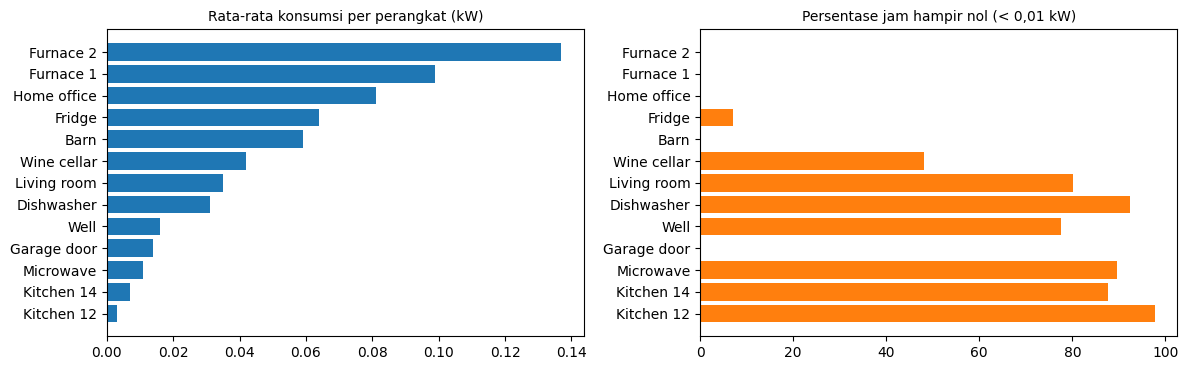

Total rata-rata per jam: terendah 0.43 kW pukul 1 | tertinggi 0.818 kW pukul 20


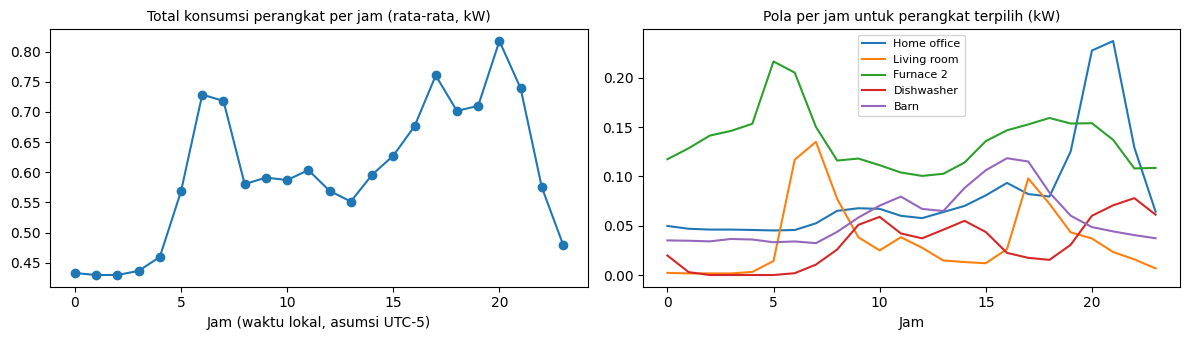

Total rata-rata hari kerja: 0.595 kW | akhir pekan: 0.607 kW


,Living room [kW],Home office [kW],Microwave [kW],Kitchen 12 [kW],Kitchen 14 [kW],Dishwasher [kW],Furnace 1 [kW],Fridge [kW],Garage door [kW],Furnace 2 [kW],Well [kW],Wine cellar [kW],Barn [kW]
Rasio akhir pekan / hari kerja,0.756,0.808,0.826,0.889,0.914,0.96,1.001,1.018,1.032,1.049,1.097,1.116,1.535


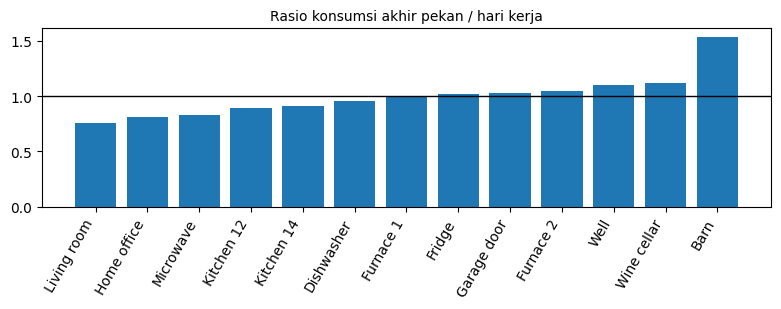

,furnace,furnace2,suhu,jam
time,,,,
1,0.221,0.235,28.773,744
2,0.225,0.234,30.371,696
3,0.120,0.172,42.439,744
4,0.095,0.122,46.649,720
5,0.049,0.085,61.527,744
6,0.026,0.067,68.078,720
7,0.061,0.110,73.260,744
8,0.069,0.127,72.518,744
9,0.031,0.078,59.747,720


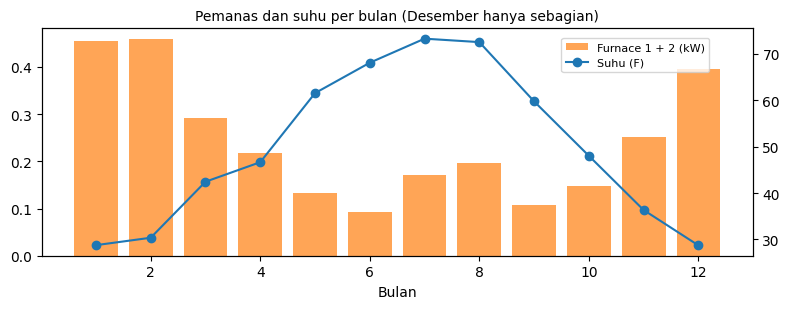

,temperature,humidity,windSpeed,cloudCover,pressure,visibility
Dishwasher [kW],-0.02,-0.00,-0.00,-0.00,0.00,-0.01
Furnace 1 [kW],-0.44,-0.07,0.14,0.02,-0.00,-0.05
Furnace 2 [kW],-0.36,-0.06,0.11,0.01,-0.00,-0.02
Home office [kW],0.01,-0.01,-0.02,-0.05,0.03,0.02
Fridge [kW],0.19,0.05,-0.04,-0.04,-0.00,0.01
Wine cellar [kW],0.35,0.07,-0.07,-0.05,0.02,0.04
Garage door [kW],0.03,-0.02,0.00,-0.02,-0.00,0.01
Kitchen 12 [kW],0.00,0.05,-0.06,-0.04,0.02,-0.01
Kitchen 14 [kW],-0.03,0.01,0.00,0.00,-0.00,-0.01
Barn [kW],-0.03,-0.00,-0.03,-0.02,0.02,0.02


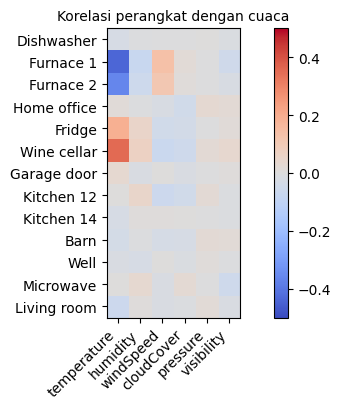

In [ ]:
import matplotlib.pyplot as plt

nama_pendek = lambda kolom: [c.replace(" [kW]", "") for c in kolom]


stat = hourly[perangkat].agg(["mean", "median", "max", "std"]).T
stat["Persen dari total"] = stat["mean"] / stat["mean"].sum() * 100
stat["Jam hampir nol (%)"] = (hourly[perangkat] < 0.01).mean() * 100
stat["Skewness"] = hourly[perangkat].skew()
stat = stat.sort_values("mean", ascending=False).round(3)
display(stat)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(nama_pendek(stat.index)[::-1], stat["mean"][::-1])
ax[0].set_title("Rata-rata konsumsi per perangkat (kW)", fontsize=10)
ax[1].barh(nama_pendek(stat.index)[::-1], stat["Jam hampir nol (%)"][::-1], color="C1")
ax[1].set_title("Persentase jam hampir nol (< 0,01 kW)", fontsize=10)
plt.tight_layout(); plt.show()


per_jam = hourly[perangkat].groupby(hourly.index.hour).mean()
total_jam = per_jam.sum(axis=1)
print("Total rata-rata per jam: terendah", round(total_jam.min(), 3), "kW pukul", int(total_jam.idxmin()),
      "| tertinggi", round(total_jam.max(), 3), "kW pukul", int(total_jam.idxmax()))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(total_jam.index, total_jam.values, marker="o")
ax[0].set_title("Total konsumsi perangkat per jam (rata-rata, kW)", fontsize=10); ax[0].set_xlabel("Jam (waktu lokal, asumsi UTC-5)")
for kol in ["Home office [kW]", "Living room [kW]", "Furnace 2 [kW]", "Dishwasher [kW]", "Barn [kW]"]:
    ax[1].plot(per_jam.index, per_jam[kol], label=kol.replace(" [kW]", ""))
ax[1].set_title("Pola per jam untuk perangkat terpilih (kW)", fontsize=10); ax[1].set_xlabel("Jam"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


akhir = hourly.index.dayofweek >= 5
rata = hourly[perangkat].groupby(akhir).mean()
rasio = (rata.loc[True] / rata.loc[False]).sort_values()
print("Total rata-rata hari kerja:", round(rata.loc[False].sum(), 3), "kW | akhir pekan:", round(rata.loc[True].sum(), 3), "kW")
display(rasio.round(3).rename("Rasio akhir pekan / hari kerja").to_frame().T)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(nama_pendek(rasio.index), rasio.values)
ax.axhline(1, color="k", lw=1); ax.set_title("Rasio konsumsi akhir pekan / hari kerja", fontsize=10)
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()


bulan = hourly.groupby(hourly.index.month).agg(furnace=("Furnace 1 [kW]", "mean"), furnace2=("Furnace 2 [kW]", "mean"),
                                               suhu=("temperature", "mean"), jam=("temperature", "size"))
display(bulan.round(3))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(bulan.index, bulan["furnace"] + bulan["furnace2"], color="C1", alpha=0.7, label="Furnace 1 + 2 (kW)")
ax2 = ax.twinx(); ax2.plot(bulan.index, bulan["suhu"], color="C0", marker="o", label="Suhu (F)")
ax.set_xlabel("Bulan"); ax.set_title("Pemanas dan suhu per bulan (Desember hanya sebagian)", fontsize=10)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88), fontsize=8)
plt.tight_layout(); plt.show()


kor = hourly[perangkat + cuaca].corr().loc[perangkat, cuaca]
display(kor.round(2))
fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(kor.values, cmap="coolwarm", vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(cuaca))); ax.set_xticklabels(cuaca, rotation=45, ha="right")
ax.set_yticks(range(len(perangkat))); ax.set_yticklabels(nama_pendek(perangkat))
fig.colorbar(im, ax=ax); ax.set_title("Korelasi perangkat dengan cuaca", fontsize=10)
plt.tight_layout(); plt.show()

# U. Analisis Data Eksploratif (EDA)

EDA dilakukan secara deskriptif pada seluruh 8.399 jam hasil agregasi (tidak ada model yang dilatih, sehingga tidak ada kebocoran data). Waktu menggunakan asumsi zona UTC-5.

## 1. Dominasi dan Sebaran Perangkat
- Pemanas mendominasi konsumsi: Furnace 2 (0,137 kW, 22,8% dari total rata-rata perangkat) dan Furnace 1 (0,099 kW, 16,6%) bersama-sama 39,4%. Berikutnya Home office (13,6%), Fridge (10,6%), dan Barn (9,8%).
- Banyak perangkat hampir selalu mati: Kitchen 12 (97,7% jam di bawah 0,01 kW), Dishwasher (92,4%), Microwave (89,6%), Kitchen 14 (87,6%), Living room (80,2%), Well (77,5%). Sebaliknya Furnace, Home office, Barn, dan Garage door hampir selalu menyala.
- Sebaran sangat miring: skewness Microwave 8,8, Kitchen 12 8,0, Barn 6,1. Garage door hampir konstan (median 0,013 kW, simpangan baku 0,006) tetapi memiliki skewness 26,4 karena lonjakan yang sangat jarang.

## 2. Pola dalam Sehari
- Konsumsi total terendah pada dini hari (sekitar 0,43 kW pukul 0 sampai 3) dan tertinggi pukul 20 (0,818 kW). Ada puncak pagi pukul 6 sampai 7 (sekitar 0,72 sampai 0,73 kW) dan puncak sore sampai malam pukul 17 sampai 21.
- Perangkat memiliki jam puncak berbeda: Furnace 2 sekitar pukul 5, Living room dan Furnace 1 sekitar pukul 7, Barn sekitar pukul 16, Home office sekitar pukul 21, dan Dishwasher sekitar pukul 22.

## 3. Hari Kerja dan Akhir Pekan
- Total konsumsi hampir sama (0,595 kW hari kerja dan 0,607 kW akhir pekan).
- Perbedaan ada pada perangkat tertentu: Barn 1,54 kali lebih tinggi pada akhir pekan, sedangkan Living room (0,76 kali), Home office (0,81 kali), dan Microwave (0,83 kali) lebih rendah.

## 4. Pola Musim dan Cuaca
- Pemanas sangat musiman: pada Januari (suhu rata-rata 28,8 F) Furnace 1 dan 2 totalnya sekitar 0,456 kW, sedangkan pada Juni (68,1 F) hanya sekitar 0,093 kW. Catatan: Desember hanya berisi 359 jam.
- Korelasi dengan suhu: Furnace 1 -0,44, Furnace 2 -0,36, Wine cellar 0,35, dan Fridge 0,19. Perangkat lain hampir tidak berkorelasi dengan cuaca (nilai mutlak di bawah sekitar 0,07), sedangkan korelasi Furnace dengan kecepatan angin 0,14 dan 0,11.

## Implikasi terhadap Masalah dan Tujuan
- Hanya pemanas, Wine cellar, dan Fridge yang dipengaruhi cuaca. Karena itu clustering dengan fitur cuaca cenderung membentuk kelompok musim (dingin dan hangat) dan cuaca berawan, bukan pola penggunaan perangkat. Ini konsisten dengan hasil K-Means pada bagian D dan seleksi fitur pada bagian R.
- Mayoritas perangkat bersifat jarang (sparse) dan sangat miring, sehingga kelompok aktivitas (misalnya Dishwasher dan Kitchen 12) kecil dan nilai ekstrem berpengaruh pada cluster berbasis jarak.
- Pola penggunaan berbeda menurut jam, sehingga fitur waktu secara teori relevan. Namun perbedaan hari kerja dan akhir pekan kecil pada total konsumsi, sejalan dengan temuan bahwa fitur waktu hampir tidak mengubah hasil cluster (bagian R).
- Garage door hampir konstan dan kurang informatif sebagai fitur, kandidat untuk dibuang pada tahap berikutnya.

In [ ]:
metrik = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
peran = {"K-Means": "Baseline", "GMM": "Kandidat 1", "Agglomerative": "Kandidat 2"}
sumber = {"K-Means": tabel_baseline, "GMM": tabel_gmm, "Agglomerative": tabel_agg}
nama_validasi = {"latih": "Hold-out 80/20: data latih (6.719 jam)", "uji": "Hold-out 80/20: data uji (1.680 jam)"}

baris = []
for model, tabel in sumber.items():
    for k in [2, 3]:
        for data in ["latih", "uji"]:
            r = tabel[(tabel["k"] == k) & (tabel["data"] == data)].iloc[0]
            baris.append({"Model": model, "Peran": peran[model], "k": k, "Metode validasi": nama_validasi[data],
                          **{m: round(r[m], 3) for m in metrik}})
        r = cv[(cv["Model"] == model) & (cv["k"] == k)]
        baris.append({"Model": model, "Peran": peran[model], "k": k, "Metode validasi": "5-Fold CV: rata-rata ± simpangan baku",
                      **{m: f"{r[m].mean():.3f} ± {r[m].std():.3f}" for m in metrik}})

tabel_hasil = pd.DataFrame(baris)
display(tabel_hasil)

,Model,Peran,k,Metode validasi,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,Baseline,2,Hold-out 80/20: data latih (6.719 jam),0.101,3.317,496.294
1,K-Means,Baseline,2,Hold-out 80/20: data uji (1.680 jam),0.101,3.23,108.386
2,K-Means,Baseline,2,5-Fold CV: rata-rata ± simpangan baku,0.100 ± 0.006,3.302 ± 0.057,99.055 ± 3.447
3,K-Means,Baseline,3,Hold-out 80/20: data latih (6.719 jam),0.099,2.81,489.419
4,K-Means,Baseline,3,Hold-out 80/20: data uji (1.680 jam),0.103,2.742,105.16
5,K-Means,Baseline,3,5-Fold CV: rata-rata ± simpangan baku,0.099 ± 0.005,2.806 ± 0.033,98.011 ± 3.772
6,GMM,Kandidat 1,2,Hold-out 80/20: data latih (6.719 jam),0.112,4.289,323.599
7,GMM,Kandidat 1,2,Hold-out 80/20: data uji (1.680 jam),0.113,4.371,66.042
8,GMM,Kandidat 1,2,5-Fold CV: rata-rata ± simpangan baku,0.100 ± 0.019,4.319 ± 0.175,64.406 ± 4.988
9,GMM,Kandidat 1,3,Hold-out 80/20: data latih (6.719 jam),0.068,4.368,250.217


# V. Tabel Hasil Eksperimen Awal

Tabel pada output sel kode di atas merangkum seluruh hasil eksperimen awal: baseline (K-Means) dan dua model kandidat (GMM dan Agglomerative Clustering), untuk k = 2 dan k = 3, dengan tiga metode validasi dan tiga metrik. Semua angka diambil dari output bagian E, G, G2, dan K, sehingga laporan dan notebook konsisten.

## Cara Membaca
- **Hold-out 80/20:** model dilatih pada 6.719 jam, lalu data uji (1.680 jam) hanya diberi label. Untuk Agglomerative, label data uji ditentukan lewat centroid terdekat sehingga nilainya tidak sepenuhnya sebanding dengan model lain.
- **5-Fold CV:** rata-rata dan simpangan baku skor pada lipatan validasi (scaler dan model dilatih ulang pada tiap fold). Simpangan baku kecil berarti hasil stabil.
- **Silhouette** dan **Calinski-Harabasz:** makin tinggi makin baik. **Davies-Bouldin:** makin rendah makin baik.

## Catatan
Tidak ada model yang unggul pada semua metrik, dan nilai Silhouette semua model rendah (di bawah sekitar 0,17). Karena itu hasil ini tidak dipakai untuk menyatakan satu model terbaik, tetapi sebagai bukti awal untuk pemilihan lebih lanjut setelah UTS.

# W. Rencana Pekerjaan Setelah UTS Menuju UAS

Rencana berikut disusun dari temuan awal pada Milestone 1. Setiap butir dikaitkan dengan bukti di notebook.

| No | Pekerjaan | Dasar temuan | Keluaran |
|----|-----------|--------------|----------|
| 1 | Memilih jumlah cluster secara sistematis dan memperluas pencarian ke k lebih besar | Metrik tidak sepakat (Calinski-Harabasz terbaik pada k=2, Davies-Bouldin dan BIC terus membaik sampai k=8, Silhouette hampir datar); k=5 menghasilkan cluster yang lebih kaya makna (bagian N dan O) | Tabel pemilihan k dengan Cross-Validation dan pertimbangan interpretabilitas |
| 2 | Memperbaiki fitur: membuang atau menguji ulang fitur waktu dan Garage door, serta mentransformasi fitur yang miring (misalnya log atau pemotongan nilai ekstrem) | Fitur waktu hampir tidak mengubah hasil (ARI 0,91 sampai 0,94, bagian R); Garage door hampir konstan dan sebaran perangkat sangat miring (bagian U); Barn tidak terwakili oleh cluster mana pun (bagian T) | Perbandingan hasil sebelum dan sesudah perbaikan fitur |
| 3 | Menentukan peran fitur cuaca: membandingkan secara adil pengelompokan dengan dan tanpa cuaca | Cuaca mengubah pengelompokan besar (ARI sekitar 0,35 sampai 0,51 tanpa cuaca) dan hanya pemanas, Wine cellar, dan Fridge yang berkorelasi dengan suhu (bagian R dan U) | Keputusan fitur beserta bukti, dengan metrik yang dihitung pada ruang evaluasi yang sama |
| 4 | Memperbaiki strategi validasi untuk data deret waktu: pembagian berdasarkan blok waktu dan validasi berurutan | Pembagian acak membuat jam berdekatan terpisah antara data latih dan uji, sehingga hasil bisa tampak terlalu baik (bagian J dan M) | Perbandingan hasil pembagian acak dan berbasis waktu |
| 5 | Menangani cluster jam aktif yang batasnya kabur: mencoba model dengan keanggotaan lunak (GMM dengan variasi kovarians) dan jumlah cluster lain | 67,8% jam pada cluster jam aktif bernilai Silhouette negatif dan sebagian besar paling mirip jam sepi (bagian S dan T) | Evaluasi cluster jam aktif dengan probabilitas keanggotaan |
| 6 | Menguji algoritma tambahan seperti DBSCAN dan variasi linkage Agglomerative | Cluster kecil (Kitchen 12, 99 jam) dan nilai ekstrem menunjukkan bentuk cluster tidak seragam (bagian T) | Tabel perbandingan algoritma tambahan terhadap baseline |
| 7 | Menguji kestabilan lebih menyeluruh: variasi random seed, jumlah fold, dan ukuran data uji | GMM k=3 tidak stabil (Silhouette 0,051 ± 0,042, satu fold negatif) dan Agglomerative bervariasi lebih besar (bagian K) | Ringkasan kestabilan tiap model |
| 8 | Tuning menyeluruh dan pemilihan model final dengan bukti berganda (tidak berdasarkan satu metrik atau visualisasi) | Tidak ada model yang unggul di semua metrik (bagian H dan V) | Model final beserta alasan metodologis dan keterbatasan |
| 9 | Menyusun interpretasi akhir cluster sebagai pola penggunaan perangkat dan mendokumentasikan batasannya | Cluster berbasis perangkat lebih mudah ditafsirkan (bagian O dan R) | Profil cluster akhir dan implikasinya |
| 10 | Menyempurnakan laporan, notebook, dan bahan presentasi | Persyaratan UAS | Laporan UAS, notebook final, dan slide presentasi |

## Urutan Pengerjaan
1. **Tahap 1:** butir 2, 3, dan 4 (perbaikan fitur dan validasi), karena memengaruhi semua eksperimen berikutnya.
2. **Tahap 2:** butir 1, 5, 6, dan 7 (pemilihan k, model tambahan, dan kestabilan).
3. **Tahap 3:** butir 8 dan 9 (tuning, pemilihan model final, dan interpretasi).
4. **Tahap 4:** butir 10 (finalisasi laporan dan presentasi).

## Catatan
- Dataset dan masalah tidak diganti, sesuai ketentuan. Perubahan hanya pada fitur, model, dan strategi evaluasi.
- Asumsi 1 baris = 1 menit dan zona waktu UTC-5 akan diperiksa kembali, misalnya terhadap dokumentasi dataset.
- Semua klaim pada tahap berikutnya harus didukung bukti dari notebook, bukan hanya dari visualisasi atau satu metrik.

# Daftar Pustaka

[1] Barker, S., Mishra, A., Irwin, D., Cecchet, E., Shenoy, P., & Albrecht, J. (2012). Smart*: An open data set and tools for enabling research in sustainable homes. Proceedings of the Workshop on Data Mining Applications in Sustainability (SustKDD), Beijing.

[2] Rajabi, A., Eskandari, M., Jabbari Ghadi, M., Li, L., Zhang, J., & Siano, P. (2020). A comparative study of clustering techniques for electrical load pattern segmentation. Renewable and Sustainable Energy Reviews, 120, 109628. https://doi.org/10.1016/j.rser.2019.109628

[3] taranvee. Smart Home Dataset with Weather Information [Data set]. Kaggle. https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information (diakses 2 November 2026).

